# Multi-Task CNN

In [1]:
%pip install torch torchvision

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import subprocess
import sys

def install_and_import(package_name, import_name=None):
    """Install package if missing and import it"""
    if import_name is None:
        import_name = package_name
    
    try:
        __import__(import_name)
    except ImportError:
        print(f"Installing {package_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package_name])
        print(f"Successfully installed {package_name}")

# Install missing packages
packages_to_check = [
    ("numpy", "numpy"),
    ("matplotlib", "matplotlib"), 
    ("pandas", "pandas"),
    ("opencv-python", "cv2"),
    ("Pillow", "PIL"),
    ("kagglehub", "kagglehub"),
    ("wandb", "wandb"),
    ("torch", "torch"),
    ("torchvision", "torchvision"),
    ("torchmetrics", "torchmetrics")
]

for package, import_name in packages_to_check:
    install_and_import(package, import_name)

# Now import everything
import numpy as np
import matplotlib.pyplot as plt
import hashlib
import pandas as pd
import random
import cv2
from PIL import Image
import os
import kagglehub
from kagglehub import KaggleDatasetAdapter
import wandb
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Dataset
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchmetrics.functional import accuracy, mean_absolute_error, mean_squared_error

os.environ["WANDB_SILENT"] = "true"

print("All packages imported successfully!")

/home/dexter/.local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/dexter/.local/lib/python3.13/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/dexter/.local/lib/python3.13/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided t

All packages imported successfully!


In [3]:
username = "gracy.garg"
# seed = 42
seed = int ( hashlib . sha256 ( username . encode () ) . hexdigest () , 16)
seed = seed % (2**32)
np.random.seed(seed)
random.seed(seed)
# print(f"Seed for {username}: {seed}")

# > Include username in plots

In [4]:
def add_username_to_plot(username="gracy.garg"):
    """
    Adds the username to the top-right corner of the current plot.
    """
    plt.text(
        0.95, 0.95, username,
        ha='right', va='top',
        transform=plt.gca().transAxes,
        fontsize=10, color='gray', alpha=0.7
    )

# Q1: Multi-Task CNN on Fashion-MNIST

## Data Loading and Preprocessing 

In [5]:
class FashionMNISTDataset(Dataset):
    """
    Custom Dataset class for Fashion-MNIST returning (image, class_label, ink_target).
    It also applies the required normalization and augmentations.
    """
    def __init__(self, subset_data, is_train=False):
        """
        Args:
            subset_data: A Subset object from torch.utils.data.random_split 
                         or the full test dataset object.
            is_train (bool): Flag to apply training-specific augmentations.
        """
        # The base dataset (either the full loaded set or a subset object)
        self.data = subset_data
        
        # Define the normalization transform (applied last)
        self.normalize = transforms.Normalize((FASHION_MEAN,), (FASHION_STD,))
        
        # Define train augmentations and base transform (applied first, if applicable)
        if is_train:
            # Augmentations for training 
            self.transform = transforms.Compose([
                transforms.RandomCrop(28, padding=4),
                # transforms.RandomRotation(5),
                transforms.ToTensor()
            ])
        else:
            # Base transform for val/test (no augmentations) 
            self.transform = transforms.ToTensor()

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        # Retrieve the original image and label from the base dataset/subset
        if isinstance(self.data, datasets.FashionMNIST):
            # Case for full dataset (like the original test set)
            img, label = self.data[idx] 
        else:
            # Case for torch.utils.data.Subset (train/val split)
            img, label = self.data[idx]

        # 1. Apply initial transform (Tensor conversion + Augmentations if training)
        img_tensor = self.transform(img)
        
        # 2. Calculate ink_target (average pixel value of the image) 
        # ink_target should be the average intensity *before* normalization, 
        # but the requirement states: "normalized pixel intensity (average pixel value of the image)".
        # We will calculate it based on the 0-1 range tensor before applying the FASHION_MEAN/STD normalization.
        ink_target = torch.mean(img_tensor)

        # 3. Apply final normalization
        normalized_img = self.normalize(img_tensor)
        
        # Return tuple (image, class_label, ink_target) 
        return normalized_img, label, ink_target

In [6]:
def load_fashion_data(train_val_ratio=0.9, batch_size=64, seed=42):
    """
    Loads Fashion-MNIST, splits the original training set into train/val (e.g., 90/10),
    and creates DataLoaders using the custom FashionMNISTDataset.

    Returns:
        tuple: (train_loader, val_loader, test_loader)
    """
    # Load original training and test sets using torchvision
    # We use the 'None' transform here, as the Custom Dataset class handles it.
    full_train_dataset = datasets.FashionMNIST(
        root='./data', train=True, download=True, transform=None
    )
    test_dataset_raw = datasets.FashionMNIST(
        root='./data', train=False, download=True, transform=None
    )
    
    # 1. Split the original training set into train and validation (90/10) 
    torch.manual_seed(seed)
    train_size = int(train_val_ratio * len(full_train_dataset))
    val_size = len(full_train_dataset) - train_size
    
    # Ensures no overlap or data leakage between splits 
    train_subset, val_subset = random_split(
        full_train_dataset, [train_size, val_size]
    )
    
    # 2. Instantiate Custom Datasets for train, val, and test
    train_dataset = FashionMNISTDataset(train_subset, is_train=True)
    val_dataset = FashionMNISTDataset(val_subset, is_train=False)
    test_dataset = FashionMNISTDataset(test_dataset_raw, is_train=False) 

    print(f"Dataset sizes: Train={len(train_dataset)}, Validation={len(val_dataset)}, Test={len(test_dataset)}")

    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, num_workers=4
    )
    val_loader = DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False, num_workers=4
    )
    test_loader = DataLoader(
        test_dataset, batch_size=batch_size, shuffle=False, num_workers=4
    )
    
    return train_loader, val_loader, test_loader

In [7]:
# Mean and Std calculated over the entire Fashion-MNIST dataset
FASHION_MEAN = 0.2860 
FASHION_STD = 0.3530

def get_transforms():
    """Defines light augmentations for training and base transforms for validation/test."""
    # Base transform for all sets (converts to tensor)
    base_transform = transforms.Compose([
        transforms.ToTensor(),
    ])

    # 1. Augmentations for Training set only [cite: 74]
    train_transform = transforms.Compose([
        # Light Augmentations [cite: 74]
        transforms.RandomCrop(28, padding=4), # Simple crop/pad
        # transforms.RandomRotation(5),        # Small rotation
                transforms.ToTensor(), # Convert to tensor (already done in Custom Dataset if using torchvision loader)
        # NOTE: Augmentations are typically done BEFORE normalization.
        # However, since the ink_target calculation depends on the ORIGINAL
        # image values for an accurate ink amount, we handle it in the Custom Dataset.
    ])

    # 2. Validation and Test sets are unaltered [cite: 75]
    val_test_transform = transforms.Compose([
        transforms.ToTensor(),
    ])
    
    return train_transform, val_test_transform

Dataset sizes: Train=54000, Validation=6000, Test=10000


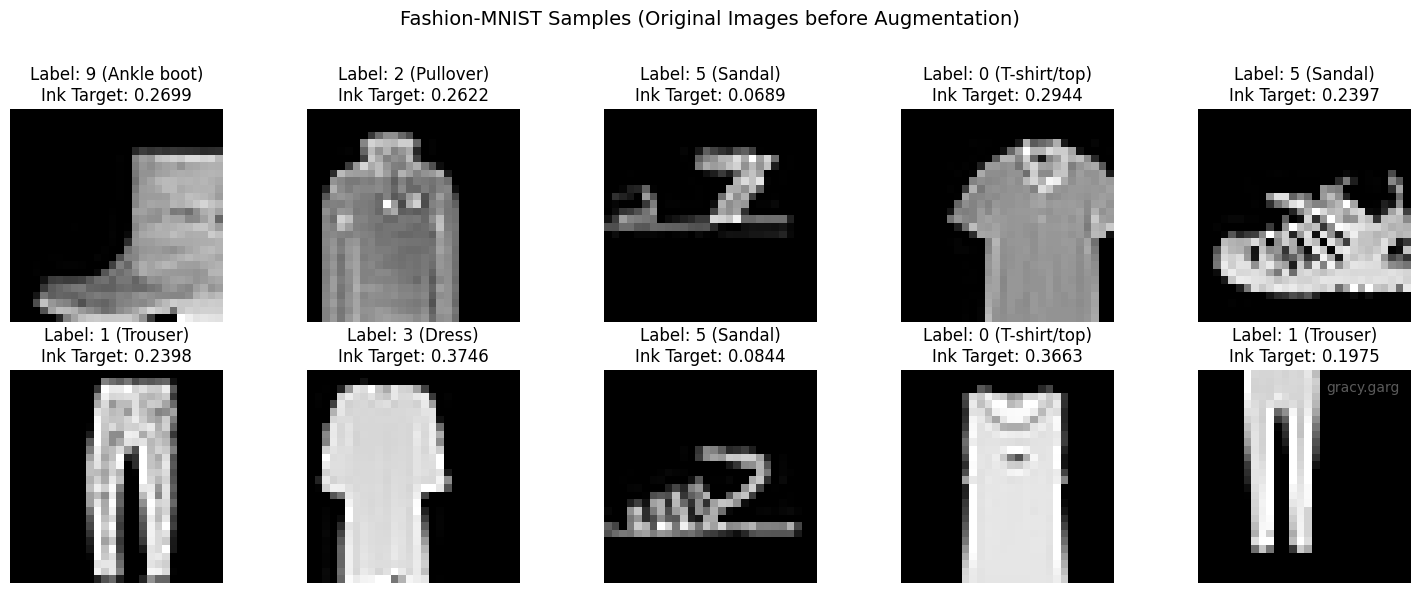

In [8]:
train_loader, val_loader, test_loader = load_fashion_data(batch_size=10, seed=42)
train_dataset = train_loader.dataset 

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle("Fashion-MNIST Samples (Original Images before Augmentation)", fontsize=14)

for i in range(10):
    # Retrieve the normalized image, label, and ink_target
    norm_image, label, ink_target = train_dataset[i]
    
    # Denormalize the image tensor for proper display (unnormalized_img = img * std + mean)
    # The image tensor is [1, 28, 28]
    denorm_image = (norm_image * FASHION_STD) + FASHION_MEAN
    
    # Convert from PyTorch Tensor to NumPy array for plotting, and remove channel dimension
    image_np = denorm_image.squeeze().numpy() 

    ax = axes[i//5, i%5]
    ax.imshow(image_np, cmap='gray')
    ax.set_title(f'Label: {label} ({class_names[label]})\nInk Target: {ink_target:.4f}')
    ax.axis('off')

add_username_to_plot(username)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

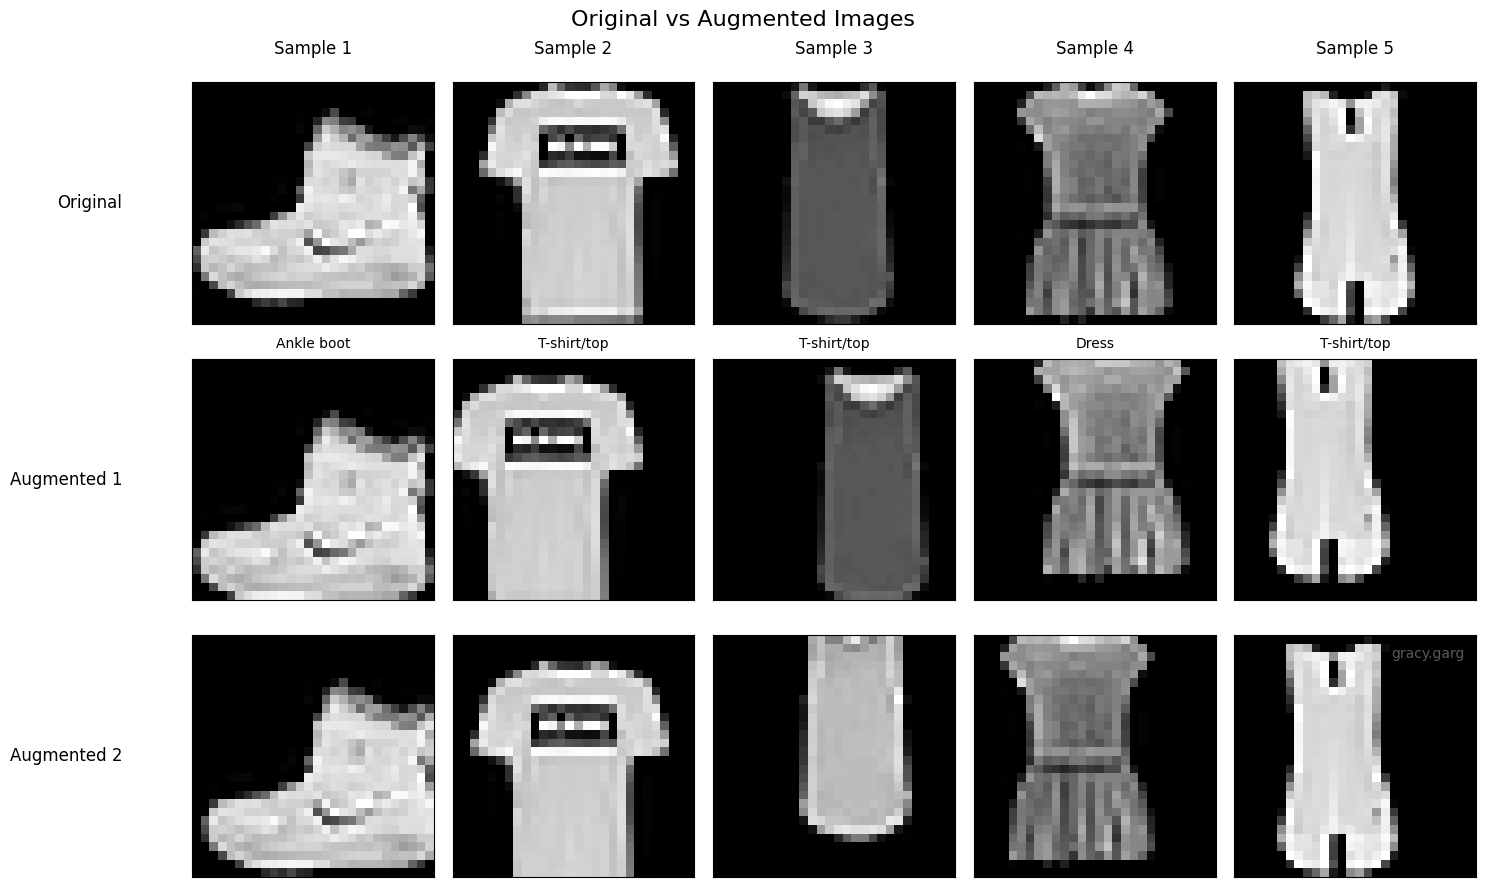

In [9]:
# Visualize images before and after augmentation
def visualize_augmentations(num_samples=5):
    """
    Visualize original images vs augmented versions to show the effect of data augmentation.
    """
    # Load the raw dataset without any transforms for original images
    raw_dataset = datasets.FashionMNIST(root='./data', train=True, download=False, transform=None)
    
    # Create augmentation transforms
    augment_transform = transforms.Compose([
        transforms.RandomCrop(28, padding=4),
        # transforms.RandomRotation(5),
        transforms.ToTensor()
    ])
    
    # Basic transform for original images
    basic_transform = transforms.ToTensor()
    
    fig, axes = plt.subplots(3, num_samples, figsize=(15, 9))
    fig.suptitle("Original vs Augmented Images", fontsize=16)
    
    # Set column titles
    for i in range(num_samples):
        axes[0, i].set_title(f'Sample {i+1}', fontsize=12, pad=20)
    
    # Set row labels
    row_labels = ['Original', 'Augmented 1', 'Augmented 2']
    for i, label in enumerate(row_labels):
        axes[i, 0].set_ylabel(label, fontsize=12, rotation=0, labelpad=50, ha='right', va='center')
    
    for i in range(num_samples):
        # Get original image and label
        original_img, label = raw_dataset[i]
        
        # Convert original to tensor for display
        original_tensor = basic_transform(original_img)
        
        # Generate two different augmented versions
        augmented_img1 = augment_transform(original_img)
        augmented_img2 = augment_transform(original_img)
        
        # Plot original image
        axes[0, i].imshow(original_tensor.squeeze(), cmap='gray')
        axes[0, i].set_xticks([])
        axes[0, i].set_yticks([])
        axes[0, i].text(0.5, -0.1, f'{class_names[label]}', 
                       transform=axes[0, i].transAxes, ha='center', fontsize=10)
        
        # Plot first augmented version
        axes[1, i].imshow(augmented_img1.squeeze(), cmap='gray')
        axes[1, i].set_xticks([])
        axes[1, i].set_yticks([])
        
        # Plot second augmented version
        axes[2, i].imshow(augmented_img2.squeeze(), cmap='gray')
        axes[2, i].set_xticks([])
        axes[2, i].set_yticks([])
    
    add_username_to_plot(username)
    plt.tight_layout()
    plt.show()

# Call the visualization function
visualize_augmentations(num_samples=5)

Detailed augmentation analysis:


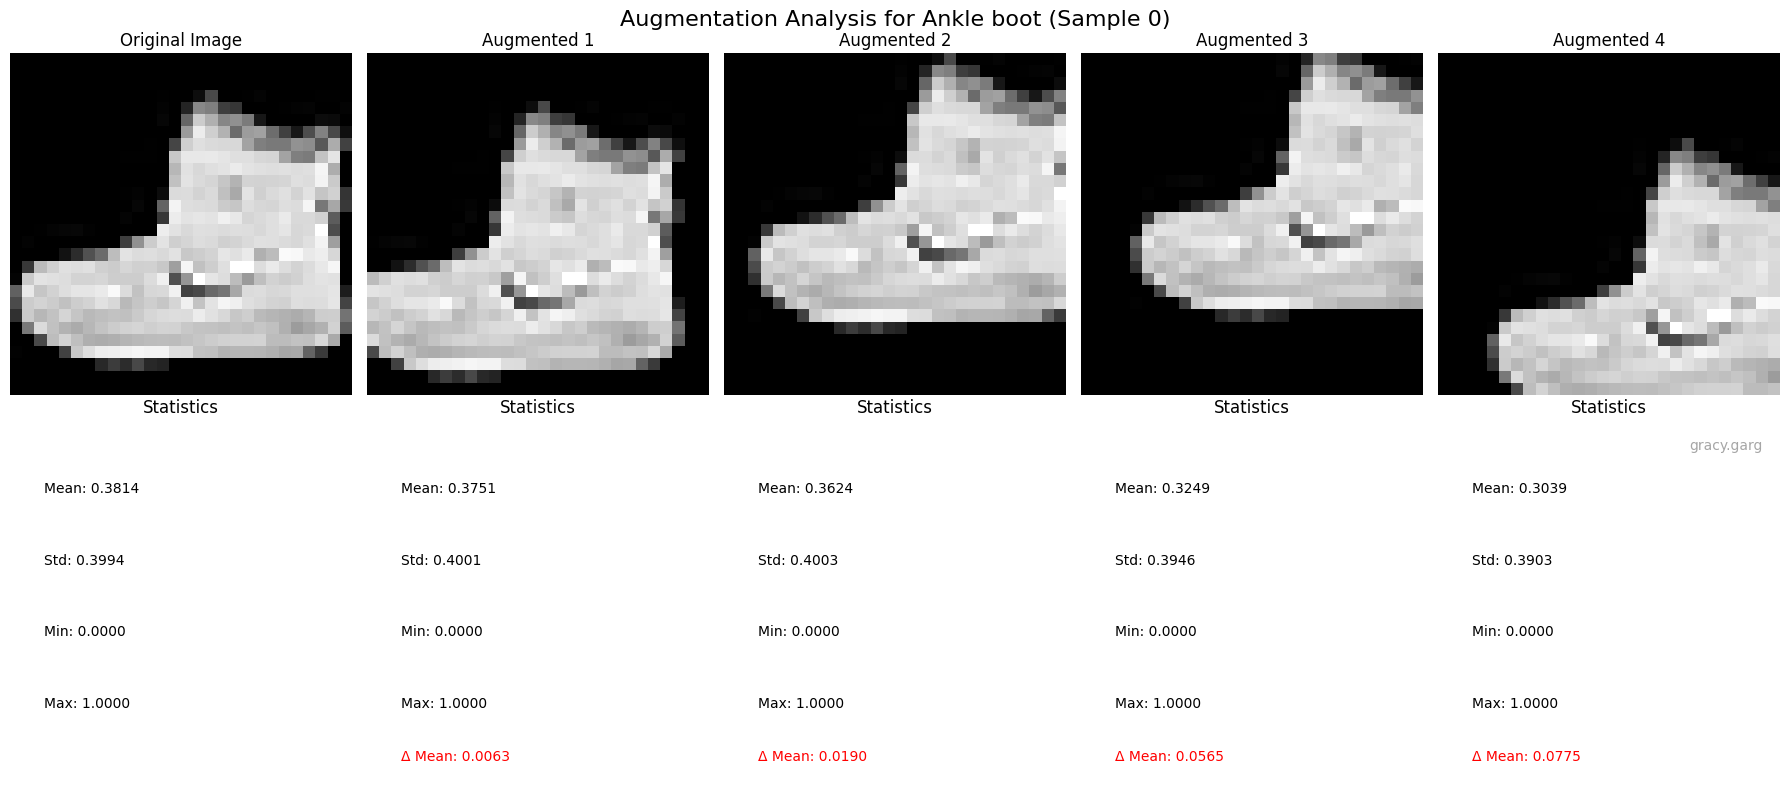

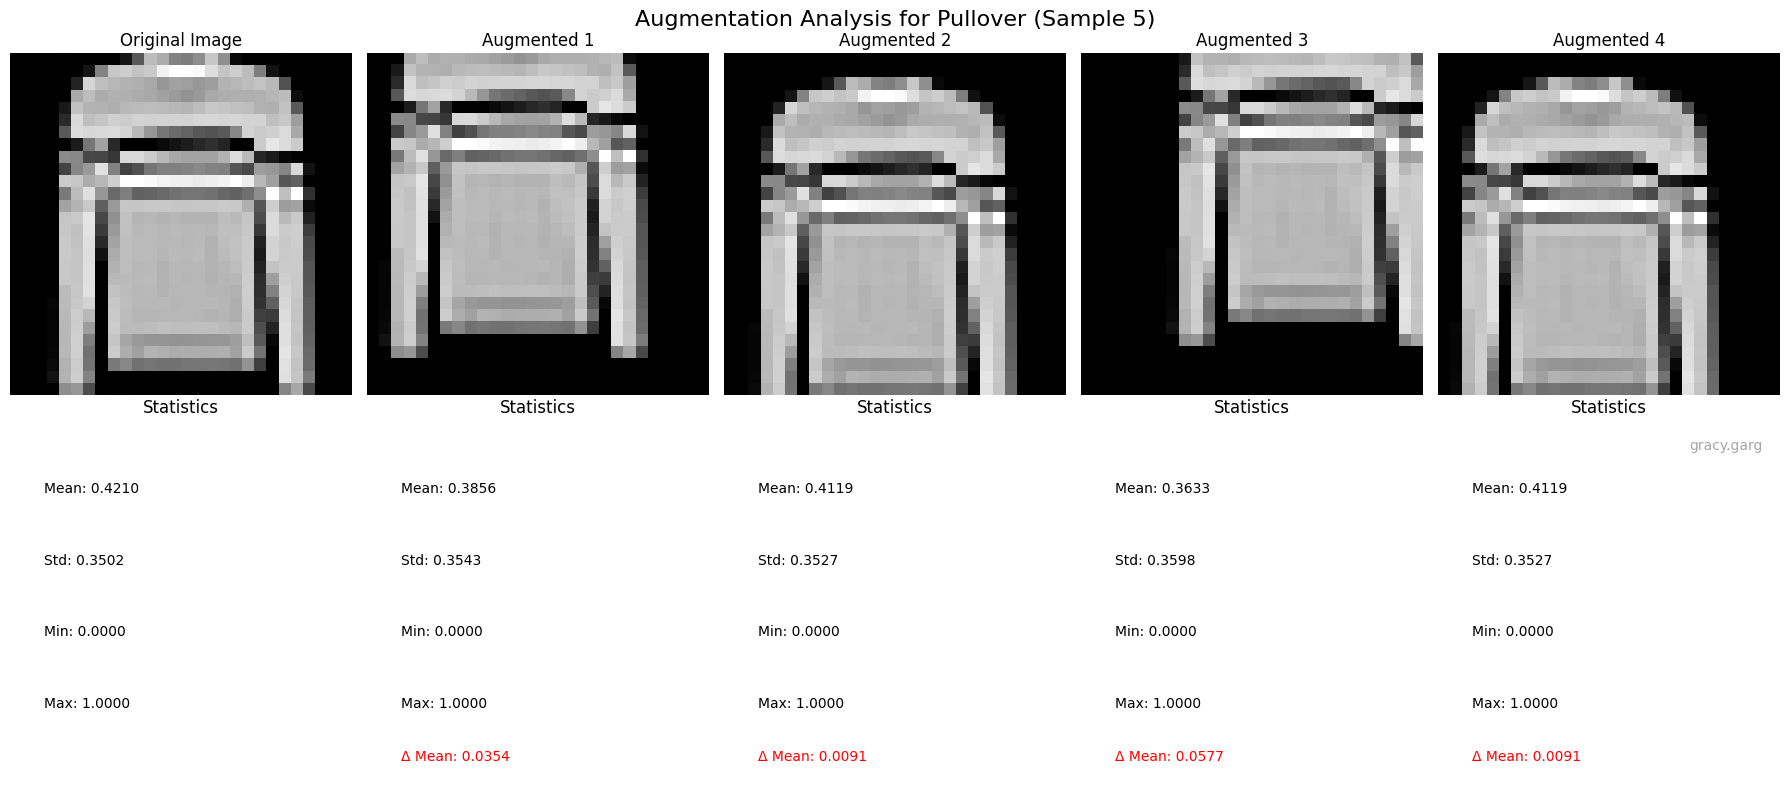

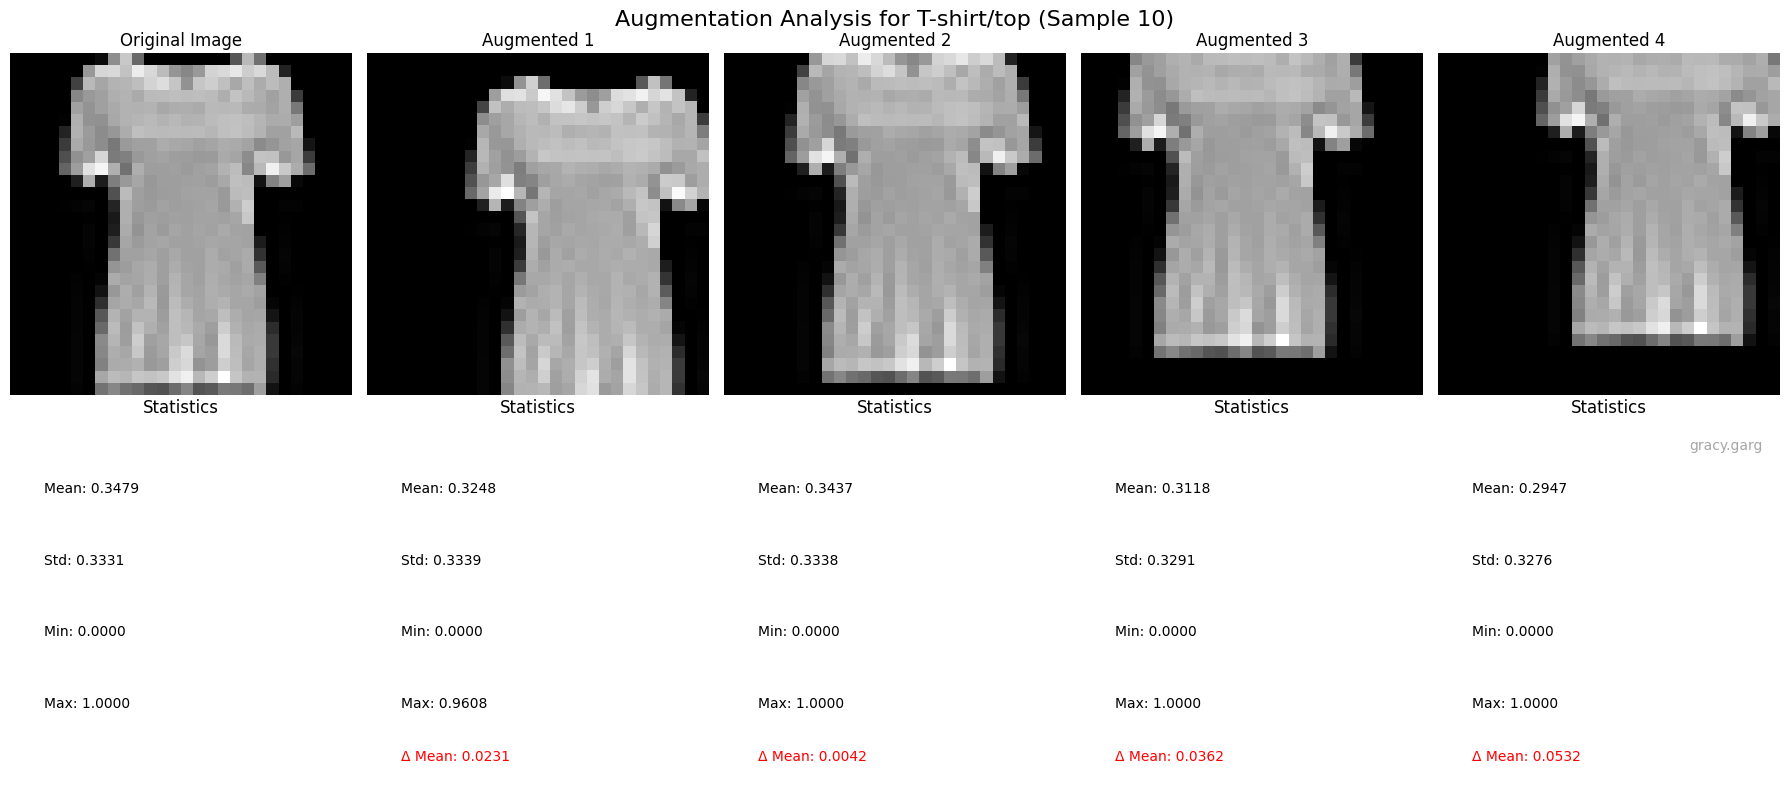

In [10]:
# Detailed comparison showing augmentation effects with statistics
def detailed_augmentation_comparison(sample_idx=0, num_augmentations=4):
    """
    Show one sample image with multiple augmented versions and statistics.
    """
    # Load raw dataset
    raw_dataset = datasets.FashionMNIST(root='./data', train=True, download=False, transform=None)
    
    # Get a specific sample
    original_img, label = raw_dataset[sample_idx]
    
    # Define augmentation transform
    augment_transform = transforms.Compose([
        transforms.RandomCrop(28, padding=4),
        # transforms.RandomRotation(5),
        transforms.ToTensor()
    ])
    
    # Basic transform
    basic_transform = transforms.ToTensor()
    original_tensor = basic_transform(original_img)
    
    # Create figure
    fig, axes = plt.subplots(2, num_augmentations + 1, figsize=(18, 8))
    fig.suptitle(f'Augmentation Analysis for {class_names[label]} (Sample {sample_idx})', fontsize=16)
    
    # Plot original image
    axes[0, 0].imshow(original_tensor.squeeze(), cmap='gray')
    axes[0, 0].set_title('Original Image', fontsize=12)
    axes[0, 0].axis('off')
    
    # Calculate original statistics
    original_mean = torch.mean(original_tensor).item()
    original_std = torch.std(original_tensor).item()
    
    axes[1, 0].text(0.1, 0.8, f'Mean: {original_mean:.4f}', transform=axes[1, 0].transAxes, fontsize=10)
    axes[1, 0].text(0.1, 0.6, f'Std: {original_std:.4f}', transform=axes[1, 0].transAxes, fontsize=10)
    axes[1, 0].text(0.1, 0.4, f'Min: {torch.min(original_tensor):.4f}', transform=axes[1, 0].transAxes, fontsize=10)
    axes[1, 0].text(0.1, 0.2, f'Max: {torch.max(original_tensor):.4f}', transform=axes[1, 0].transAxes, fontsize=10)
    axes[1, 0].set_title('Statistics', fontsize=12)
    axes[1, 0].axis('off')
    
    # Generate and plot augmented versions
    for i in range(num_augmentations):
        # Generate augmented image
        aug_img = augment_transform(original_img)
        
        # Plot augmented image
        axes[0, i + 1].imshow(aug_img.squeeze(), cmap='gray')
        axes[0, i + 1].set_title(f'Augmented {i + 1}', fontsize=12)
        axes[0, i + 1].axis('off')
        
        # Calculate augmented statistics
        aug_mean = torch.mean(aug_img).item()
        aug_std = torch.std(aug_img).item()
        
        # Show statistics
        axes[1, i + 1].text(0.1, 0.8, f'Mean: {aug_mean:.4f}', transform=axes[1, i + 1].transAxes, fontsize=10)
        axes[1, i + 1].text(0.1, 0.6, f'Std: {aug_std:.4f}', transform=axes[1, i + 1].transAxes, fontsize=10)
        axes[1, i + 1].text(0.1, 0.4, f'Min: {torch.min(aug_img):.4f}', transform=axes[1, i + 1].transAxes, fontsize=10)
        axes[1, i + 1].text(0.1, 0.2, f'Max: {torch.max(aug_img):.4f}', transform=axes[1, i + 1].transAxes, fontsize=10)
        
        # Calculate difference from original
        mean_diff = abs(aug_mean - original_mean)
        axes[1, i + 1].text(0.1, 0.05, f'Δ Mean: {mean_diff:.4f}', transform=axes[1, i + 1].transAxes, 
                           fontsize=10, color='red')
        axes[1, i + 1].set_title('Statistics', fontsize=12)
        axes[1, i + 1].axis('off')
    
    add_username_to_plot(username)
    plt.tight_layout()
    plt.show()

# Show detailed comparison for a few different samples
print("Detailed augmentation analysis:")
detailed_augmentation_comparison(sample_idx=0)  # Ankle boot
detailed_augmentation_comparison(sample_idx=5)  # Pullover
detailed_augmentation_comparison(sample_idx=10)  # Tshirt

# Model Implementation: Multi-Task CNN

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MultiTaskCNN(nn.Module):
    """
    A Convolutional Neural Network with a shared backbone that branches into 
    two heads for Classification (10 classes) and Regression (ink_target).
    """
    def __init__(self, num_classes=10, base_filters=32, dropout_rate=0.2):
        """
        Initializes the Multi-Task CNN.

        Args:
            num_classes (int): Number of clothing categories (10 for Fashion-MNIST).
            base_filters (int): Number of filters in the first convolutional layer.
            dropout_rate (float): Dropout rate applied after the shared backbone.
        """
        super(MultiTaskCNN, self).__init__()
        
        # --- Shared Convolutional Backbone (2-3 Conv-BatchNorm-ReLU-Pool blocks) ---
        
        # Block 1: Input (1x28x28) -> Output (base_filters x 14 x 14)
        self.conv1 = nn.Conv2d(1, base_filters, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(base_filters)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Block 2: Input (base_filters x 14 x 14) -> Output (2*base_filters x 7 x 7)
        self.conv2 = nn.Conv2d(base_filters, 2 * base_filters, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(2 * base_filters)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Block 3: Input (2*base_filters x 7 x 7) -> Output (4*base_filters x 3 x 3)
        # Note: MaxPool(2x2) on 7x7 gives 3x3 with one pixel drop
        self.conv3 = nn.Conv2d(2 * base_filters, 4 * base_filters, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(4 * base_filters)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Determine the size of the flattened feature map after the backbone:
        # 28x28 -> 14x14 -> 7x7 -> 3x3 (after 3 pools)
        # Flattened size = 4 * base_filters * 3 * 3 
        flatten_size = 4 * base_filters * 3 * 3
        
        # Dropout layer after the backbone
        self.dropout = nn.Dropout(dropout_rate)

        # --- Classification Head (outputs logits [B, 10]) ---
        self.cls_fc1 = nn.Linear(flatten_size, 128)
        self.cls_fc2 = nn.Linear(128, num_classes) # Final output is logits (no softmax)

        # --- Regression Head (outputs scalar values [B, 1]) ---
        self.reg_fc1 = nn.Linear(flatten_size, 128)
        self.reg_fc2 = nn.Linear(128, 1) # Final output is a scalar (1D)

    def forward(self, x, return_features=False):
        """
        Forward pass through the shared backbone and two heads.

        Args:
            x (torch.Tensor): Input image tensor [B, 1, 28, 28].
            return_features (bool): If True, returns intermediate feature maps.

        Returns:
            tuple: (cls_logits, reg_prediction) 
                   or (cls_logits, reg_prediction, intermediate_features)
        """
        # Dictionary to store intermediate feature maps
        features = {}

        # 1. Block 1
        x = self.pool1(F.relu(self.bn1(self.conv1(x))))
        features['block1'] = x
        
        # 2. Block 2
        x = self.pool2(F.relu(self.bn2(self.conv2(x))))
        features['block2'] = x

        # 3. Block 3
        x = self.pool3(F.relu(self.bn3(self.conv3(x))))
        features['block3'] = x

        # 4. Shared Fully Connected Input
        shared_features = self.dropout(x.view(x.size(0), -1)) # Flatten

        # 5. Classification Head
        cls_logits = F.relu(self.cls_fc1(shared_features))
        cls_logits = self.cls_fc2(cls_logits)

        # 6. Regression Head
        reg_pred = F.relu(self.reg_fc1(shared_features))
        reg_pred = self.reg_fc2(reg_pred)
        
        if return_features:
            return cls_logits, reg_pred, features
        else:
            return cls_logits, reg_pred

In [ ]:
def compute_joint_loss(cls_logits, reg_predictions, cls_targets, reg_targets, lambda1, lambda2):
    """
    Computes the weighted joint loss for the multi-task model.

    Args:
        cls_logits (torch.Tensor): Output logits from the classification head.
        reg_predictions (torch.Tensor): Output predictions from the regression head.
        cls_targets (torch.Tensor): Ground truth integer class labels.
        reg_targets (torch.Tensor): Ground truth ink_target values.
        lambda1 (float): Weighting factor for classification loss (Cross-Entropy).
        lambda2 (float): Weighting factor for regression loss (MSE).

    Returns:
        tuple: (total_loss, cls_loss, reg_loss)
    """
    # L_classification is Cross-Entropy loss 
    cls_loss = F.cross_entropy(cls_logits, cls_targets)

    # L_regression is Mean Squared Error (MSE) loss 
    # Ensure reg_predictions and reg_targets have matching shapes (e.g., [B, 1] and [B, 1])
    reg_loss = F.mse_loss(reg_predictions.squeeze(1), reg_targets)
    
    # Total loss: L = lambda1 * L_CE + lambda2 * L_MSE 
    total_loss = lambda1 * cls_loss + lambda2 * reg_loss
    
    return total_loss, cls_loss, reg_loss

In [13]:

# --- Metrics Calculation Helper ---
def compute_val_metrics(cls_logits, reg_predictions, cls_targets, reg_targets):
    """Calculates classification Accuracy and Regression RMSE/MAE."""
    
    # Classification Metrics
    # Get the class with the highest logit
    cls_preds = torch.argmax(cls_logits, dim=1)
    val_acc = accuracy(cls_preds, cls_targets, task="multiclass", num_classes=10)
    
    # Regression Metrics
    val_mae = mean_absolute_error(reg_predictions.squeeze(1), reg_targets)
    # RMSE is the square root of MSE
    val_rmse = torch.sqrt(mean_squared_error(reg_predictions.squeeze(1), reg_targets))
    
    return val_acc, val_mae, val_rmse

def run_experiment(config, train_loader, val_loader, device, num_epochs=15):
    """
    Runs a single multi-task training experiment and logs results to wandb.
    """
    # 1. Initialize run with configuration
    run = wandb.init(
        project="SMAI-A4",
        name=f"L1_{config['lambda1']}_L2_{config['lambda2']}_{config['optimizer']}",
        config=config,
        reinit=True  # Allow multiple runs in same session
    )

    # 2. Setup Model, Optimizer, and Loss factors
    model = MultiTaskCNN(base_filters=config['base_filters'], dropout_rate=config['dropout_rate']).to(device)

    if config['optimizer'] == 'Adam':
        optimizer = torch.optim.Adam(model.parameters(), lr=config['learning_rate'])
    elif config['optimizer'] == 'AdamW':
        optimizer = torch.optim.AdamW(model.parameters(), lr=config['learning_rate'])
    else: # SGD
        optimizer = torch.optim.SGD(model.parameters(), lr=config['learning_rate'], momentum=0.9)

    lambda1 = config['lambda1']
    lambda2 = config['lambda2']

    print(f"Starting Run: L1={lambda1}, L2={lambda2}")

    # 3. Training and Validation Loop
    best_val_loss = float('inf')
    # Define a path for the checkpoint (use wandb run ID for unique naming)
    checkpoint_path = f"best_model_cls_{run.id}.pth" 

    for epoch in range(1, num_epochs + 1):
        model.train()
        running_total_loss = 0.0

        # --- Training Step ---
        for images, cls_targets, reg_targets in train_loader:
            # Move data to device
            images = images.to(device)
            cls_targets = cls_targets.to(device)
            reg_targets = reg_targets.to(device).float()

            # Forward pass
            cls_logits, reg_predictions = model(images)

            # Calculate losses
            total_loss, cls_loss, reg_loss = compute_joint_loss(
                cls_logits, reg_predictions, cls_targets, reg_targets, lambda1, lambda2
            )

            # Backward pass
            optimizer.zero_grad()
            total_loss.backward()
            optimizer.step()

            running_total_loss += total_loss.item()

        # Log training losses at end of epoch
        avg_train_loss = running_total_loss / len(train_loader)
        wandb.log({
            "train/total_loss": avg_train_loss,
            "epoch": epoch
        })

        # --- Validation Step ---
        model.eval()
        val_cls_losses, val_reg_losses = [], []
        all_cls_preds, all_cls_targets, all_reg_preds, all_reg_targets = [], [], [], []

        with torch.no_grad():
            for images, cls_targets, reg_targets in val_loader:
                # Move data to device
                images = images.to(device)
                cls_targets = cls_targets.to(device)
                reg_targets = reg_targets.to(device).float()

                cls_logits, reg_predictions = model(images)

                total_loss, cls_loss, reg_loss = compute_joint_loss(
                    cls_logits, reg_predictions, cls_targets, reg_targets, lambda1, lambda2
                )

                val_cls_losses.append(cls_loss.item())
                val_reg_losses.append(reg_loss.item())

                # Store tensors for overall metrics calculation
                all_cls_preds.append(cls_logits.cpu())
                all_cls_targets.append(cls_targets.cpu())
                all_reg_preds.append(reg_predictions.cpu())
                all_reg_targets.append(reg_targets.cpu())

        # Calculate overall metrics
        val_acc, val_mae, val_rmse = compute_val_metrics(
            torch.cat(all_cls_preds), torch.cat(all_reg_preds),
            torch.cat(all_cls_targets), torch.cat(all_reg_targets).float()
        )

        avg_val_cls_loss = np.mean(val_cls_losses)
        avg_val_reg_loss = np.mean(val_reg_losses)
        avg_val_total_loss = lambda1 * avg_val_cls_loss + lambda2 * avg_val_reg_loss

        wandb.log({
            "val/total_loss": avg_val_total_loss,
            "val/ce_loss": avg_val_cls_loss,
            "val/mse_loss": avg_val_reg_loss,
            "val/accuracy": val_acc,
            "val/mae": val_mae,
            "val/rmse": val_rmse,
        }, step=epoch)

        # Model Selection (Save best checkpoint based on total validation loss)
        if avg_val_total_loss < best_val_loss:
            best_val_loss = avg_val_total_loss
            # Save the entire model state dictionary
            torch.save(model.state_dict(), checkpoint_path)
            print(f"Saved new best model checkpoint at epoch {epoch}")

    print(f"Training completed. Best validation loss: {best_val_loss:.4f}")
    
    # Log final summary
    wandb.summary['best_val_loss'] = best_val_loss
    wandb.summary['final_val_acc'] = val_acc.item() if hasattr(val_acc, 'item') else val_acc
    wandb.summary['final_val_rmse'] = val_rmse.item() if hasattr(val_rmse, 'item') else val_rmse
    
    wandb.finish()
    return best_val_loss

# Hyperparameter Tuning and wandb Logging

In [ ]:

# --- Device Setup ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

# --- Load Data ---
try:
    train_loader, val_loader, test_loader = load_fashion_data(
        train_val_ratio=0.9,
        batch_size=128,
        seed=42
    )
    print("Data loaders initialized successfully.")
except Exception as e:
    print(f"Error loading data: {e}. Ensure load_fashion_data() is defined properly.")


def evaluate_model(model, val_loader, config, device):
    """
    Evaluates the model on validation data and returns metrics.
    """
    model.eval()
    total_loss = 0.0
    all_cls_preds = []
    all_cls_targets = []
    all_reg_preds = []
    all_reg_targets = []
    
    with torch.no_grad():
        for imgs, labels, ink_vals in val_loader:
            imgs = imgs.to(device)
            labels = labels.to(device)
            ink_vals = ink_vals.to(device).float()
            
            class_logits, ink_preds = model(imgs)
            
            # Calculate losses
            ce_loss = torch.nn.functional.cross_entropy(class_logits, labels)
            mse_loss = torch.nn.functional.mse_loss(ink_preds.squeeze(), ink_vals)
            loss = config.lambda1 * ce_loss + config.lambda2 * mse_loss
            
            total_loss += loss.item()
            
            # Store predictions and targets for metric calculation
            all_cls_preds.append(class_logits.cpu())
            all_cls_targets.append(labels.cpu())
            all_reg_preds.append(ink_preds.cpu())
            all_reg_targets.append(ink_vals.cpu())
    
    # Calculate metrics
    all_cls_preds = torch.cat(all_cls_preds)
    all_cls_targets = torch.cat(all_cls_targets)
    all_reg_preds = torch.cat(all_reg_preds)
    all_reg_targets = torch.cat(all_reg_targets)
    
    # Classification accuracy
    cls_preds = torch.argmax(all_cls_preds, dim=1)
    val_acc = accuracy(cls_preds, all_cls_targets, task="multiclass", num_classes=10)
    
    # Regression RMSE
    val_rmse = torch.sqrt(mean_squared_error(all_reg_preds.squeeze(), all_reg_targets))
    
    avg_val_loss = total_loss / len(val_loader)
    
    return avg_val_loss, val_acc.item(), val_rmse.item()


# --- Define Sweep Configuration ---
sweep_config = {
    'method': 'grid',       
    'metric': {
        'name': 'val_total_loss',   
        'goal': 'minimize'
    },
    'parameters': {
        'lambda1': {
            'values': [0.1, 0.5, 1.0, 2.0]
        },
        'lambda2': {
            'values': [0.5, 1.0, 2.0]
        },
        'learning_rate': {
            'values': [1e-4, 5e-4, 1e-3, 3e-3]
        },
        'optimizer': {
            'values': ['Adam', 'AdamW', 'SGD']
        },
        'dropout_rate': {
            'values': [0.3, 0.4, 0.5]
        },
        'base_filters': {
            'values': [32, 64]
        },
        'batch_size': {
            'values': [64, 128]
        },
        'num_epochs': {
            'value': 5
        }
    }
}

# --- Initialize Sweep ---
# sweep_id = wandb.sweep(sweep_config, project="SMAI-A4")

# Replace the train_sweep function with a wrapper that calls run_experiment
def train_sweep():
    wandb.init()
    config = wandb.config
    
    # Convert wandb config to dict for run_experiment
    config_dict = {
        'lambda1': config.lambda1,
        'lambda2': config.lambda2,
        'learning_rate': config.learning_rate,
        'optimizer': config.optimizer,
        'dropout_rate': config.dropout_rate,
        'base_filters': config.base_filters,
        'batch_size': config.batch_size,
        'num_epochs': config.num_epochs
    }
    
    # Create data loaders with the config batch size
    train_loader_sweep, val_loader_sweep, _ = load_fashion_data(
        train_val_ratio=0.9,
        batch_size=config.batch_size,
        seed=42
    )
    
    # Call the more complete run_experiment function
    run_experiment(config_dict, train_loader_sweep, val_loader_sweep, device, config.num_epochs)

# --- Run Sweep Agent ---
# Each agent automatically tries one configuration
# wandb.agent(sweep_id, function=train_sweep, count=1000)  # increase count to explore more configs


Using device: CPU
Dataset sizes: Train=54000, Validation=6000, Test=10000
Data loaders initialized successfully.
Create sweep with ID: l78wefrx
Sweep URL: https://wandb.ai/gracygarg6516-iiit-hyderabad/SMAI-A4/sweeps/l78wefrx


In [15]:
%run 1.py

Using device: CPU
Dataset sizes: Train=54000, Validation=6000, Test=10000
Data loaders initialized successfully.
Create sweep with ID: 2hi53gi2
Sweep URL: https://wandb.ai/gracygarg6516-iiit-hyderabad/SMAI-A4/sweeps/2hi53gi2
Dataset sizes: Train=54000, Validation=6000, Test=10000
Starting Run: L1=1, L2=2
Saved new best model checkpoint at epoch 1
Saved new best model checkpoint at epoch 2
Saved new best model checkpoint at epoch 3
Saved new best model checkpoint at epoch 4
Saved new best model checkpoint at epoch 5
Training completed. Best validation loss: 0.3120
Best model saved as: model_checkpoints/BEST_L11_L22_Adam_loss0.3120_20251103_210812.pth
Dataset sizes: Train=54000, Validation=6000, Test=10000
Starting Run: L1=0.1, L2=2
Saved new best model checkpoint at epoch 1
Saved new best model checkpoint at epoch 2
Saved new best model checkpoint at epoch 3
Saved new best model checkpoint at epoch 5
Training completed. Best validation loss: 0.0352
Best model saved as: model_checkpoints

# Feature Map Visualization

Loading Best Classification Model for Visualization...
Successfully loaded trained weights from model_checkpoints/BEST_L10.1_L20.5_AdamW_loss0.0304_20251103_211601.pth

=== Test Image 1 ===
Ground Truth: Sneaker
Predicted: Sneaker
Ink Target: 0.2983
Regression Prediction: 0.3120


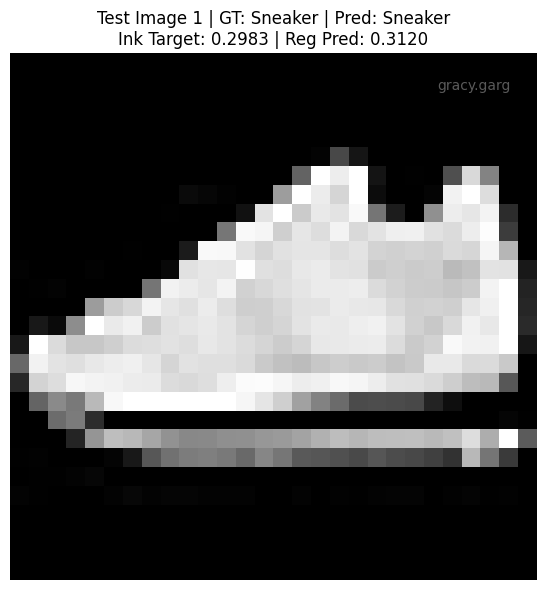


block1: 64 channels, Feature map size: 14x14


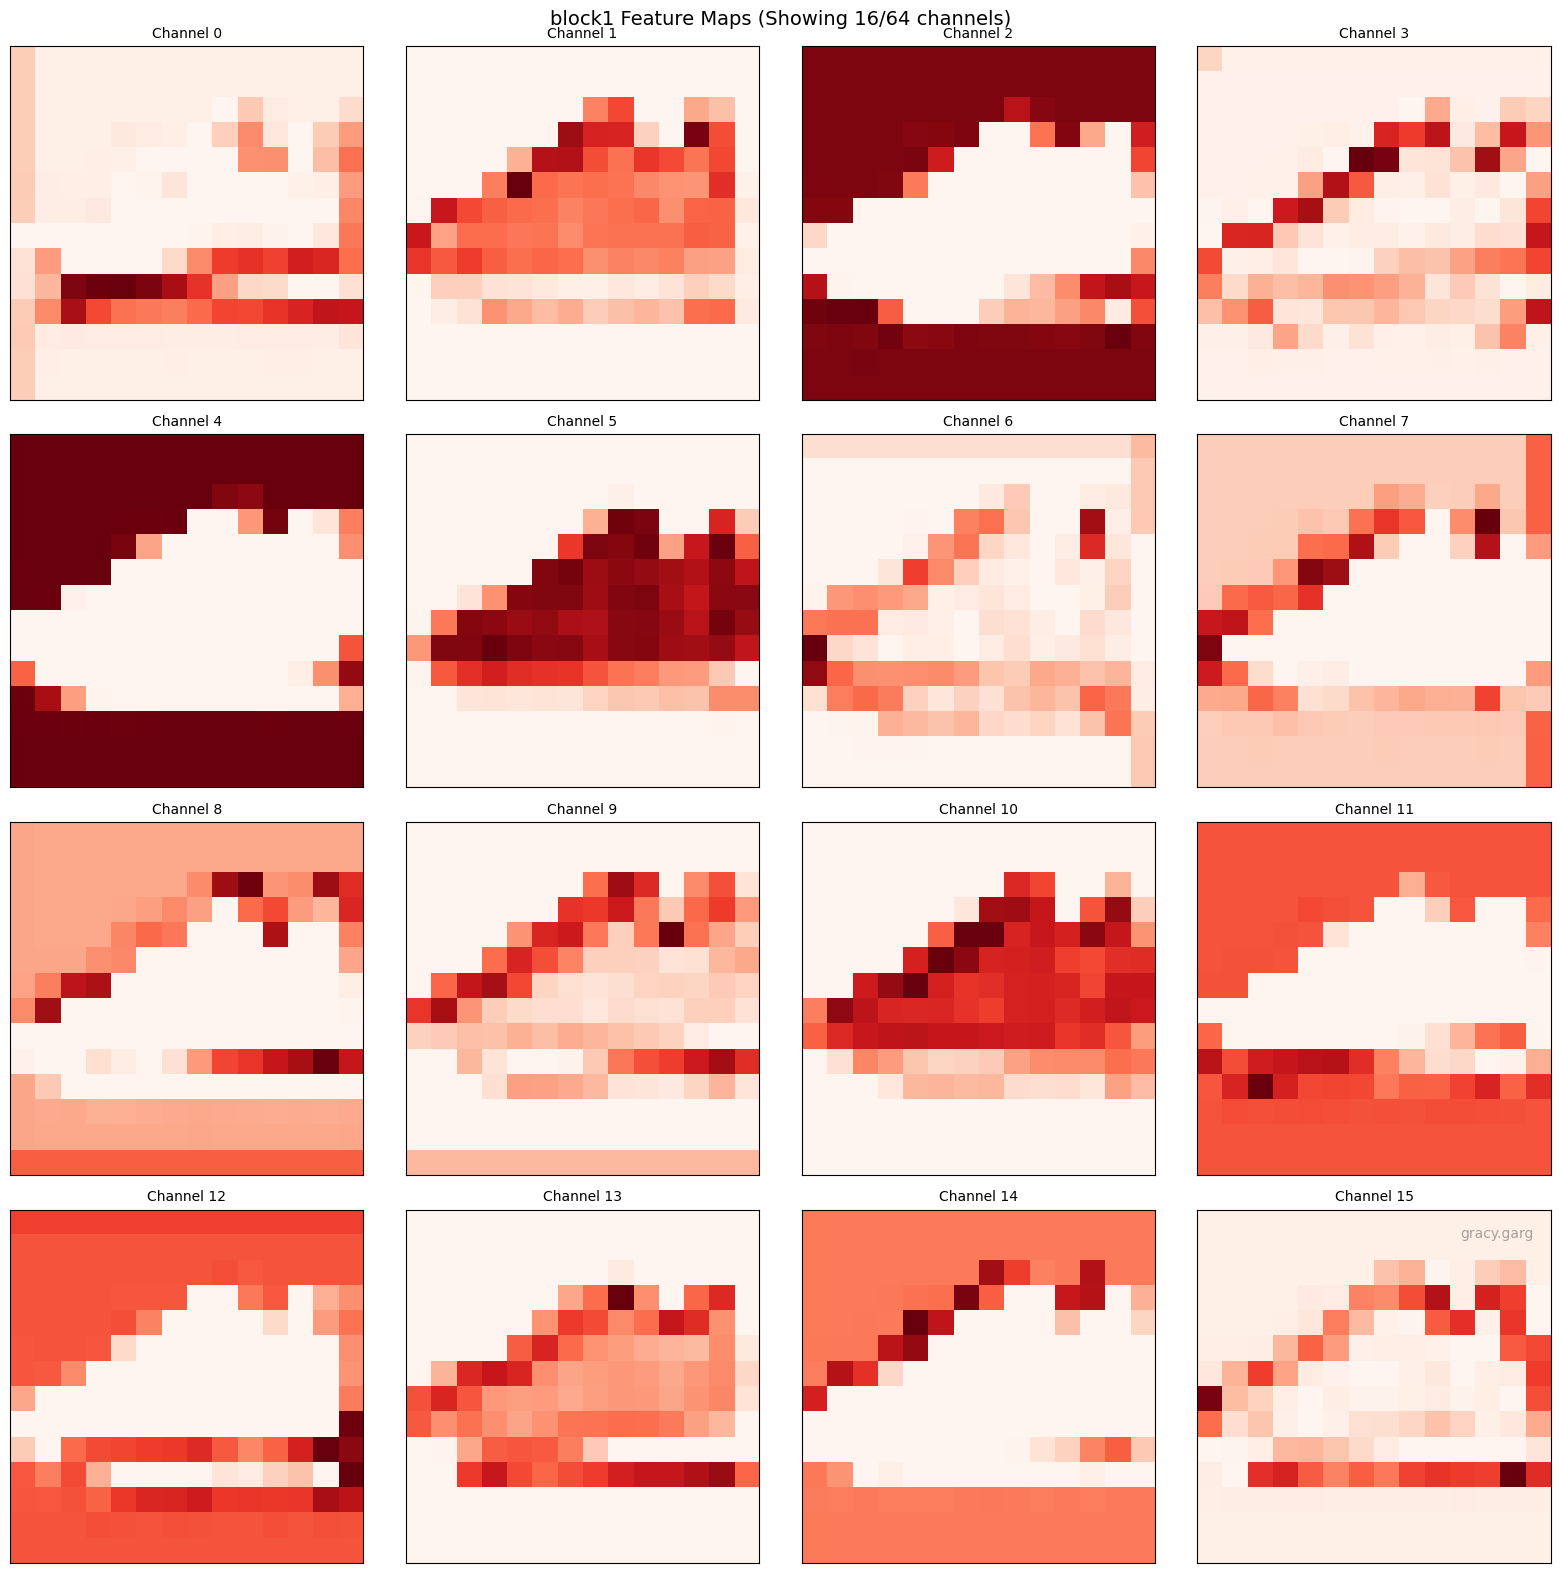


block2: 128 channels, Feature map size: 7x7


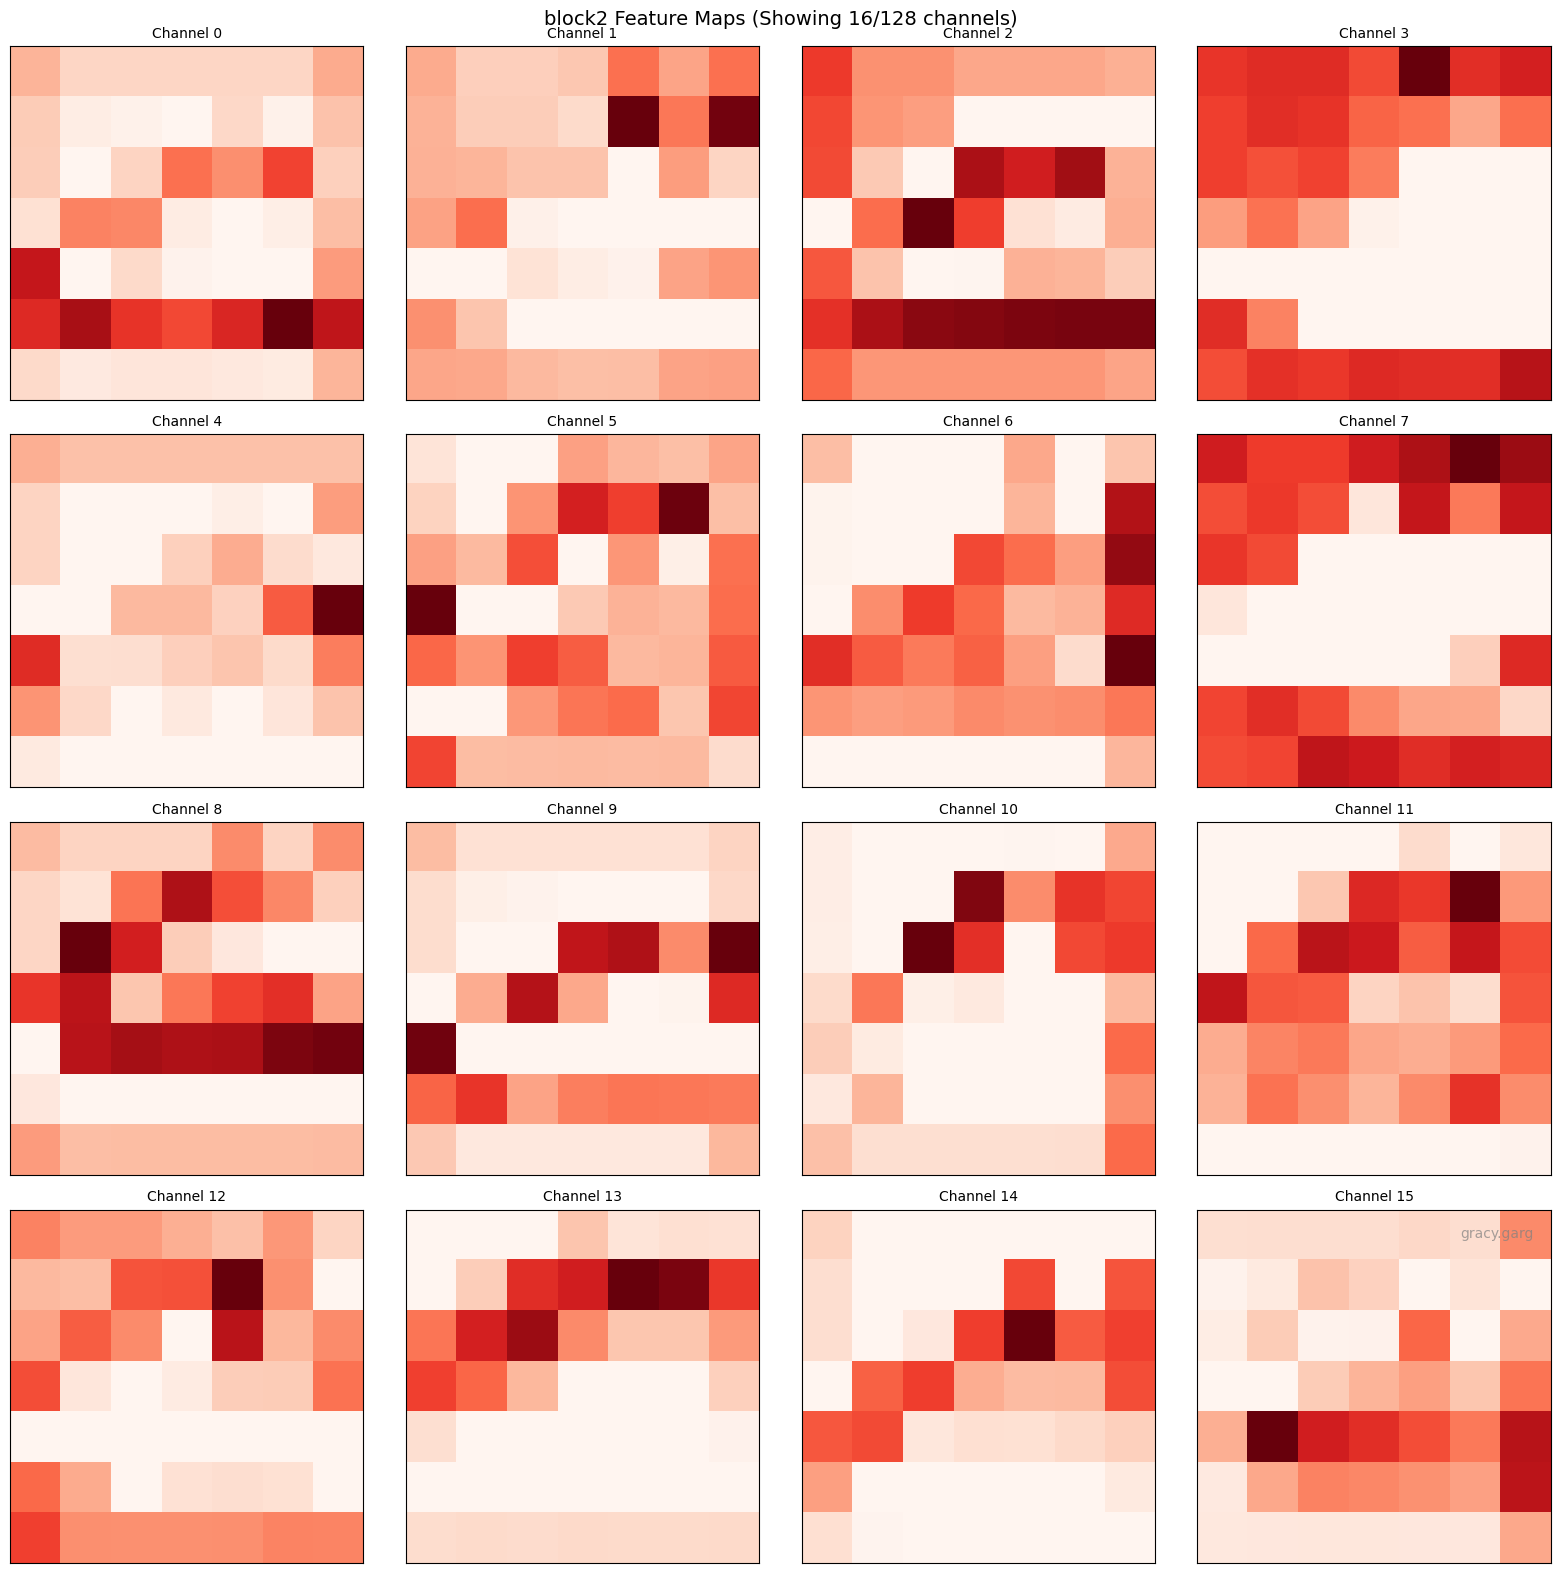


block3: 256 channels, Feature map size: 3x3


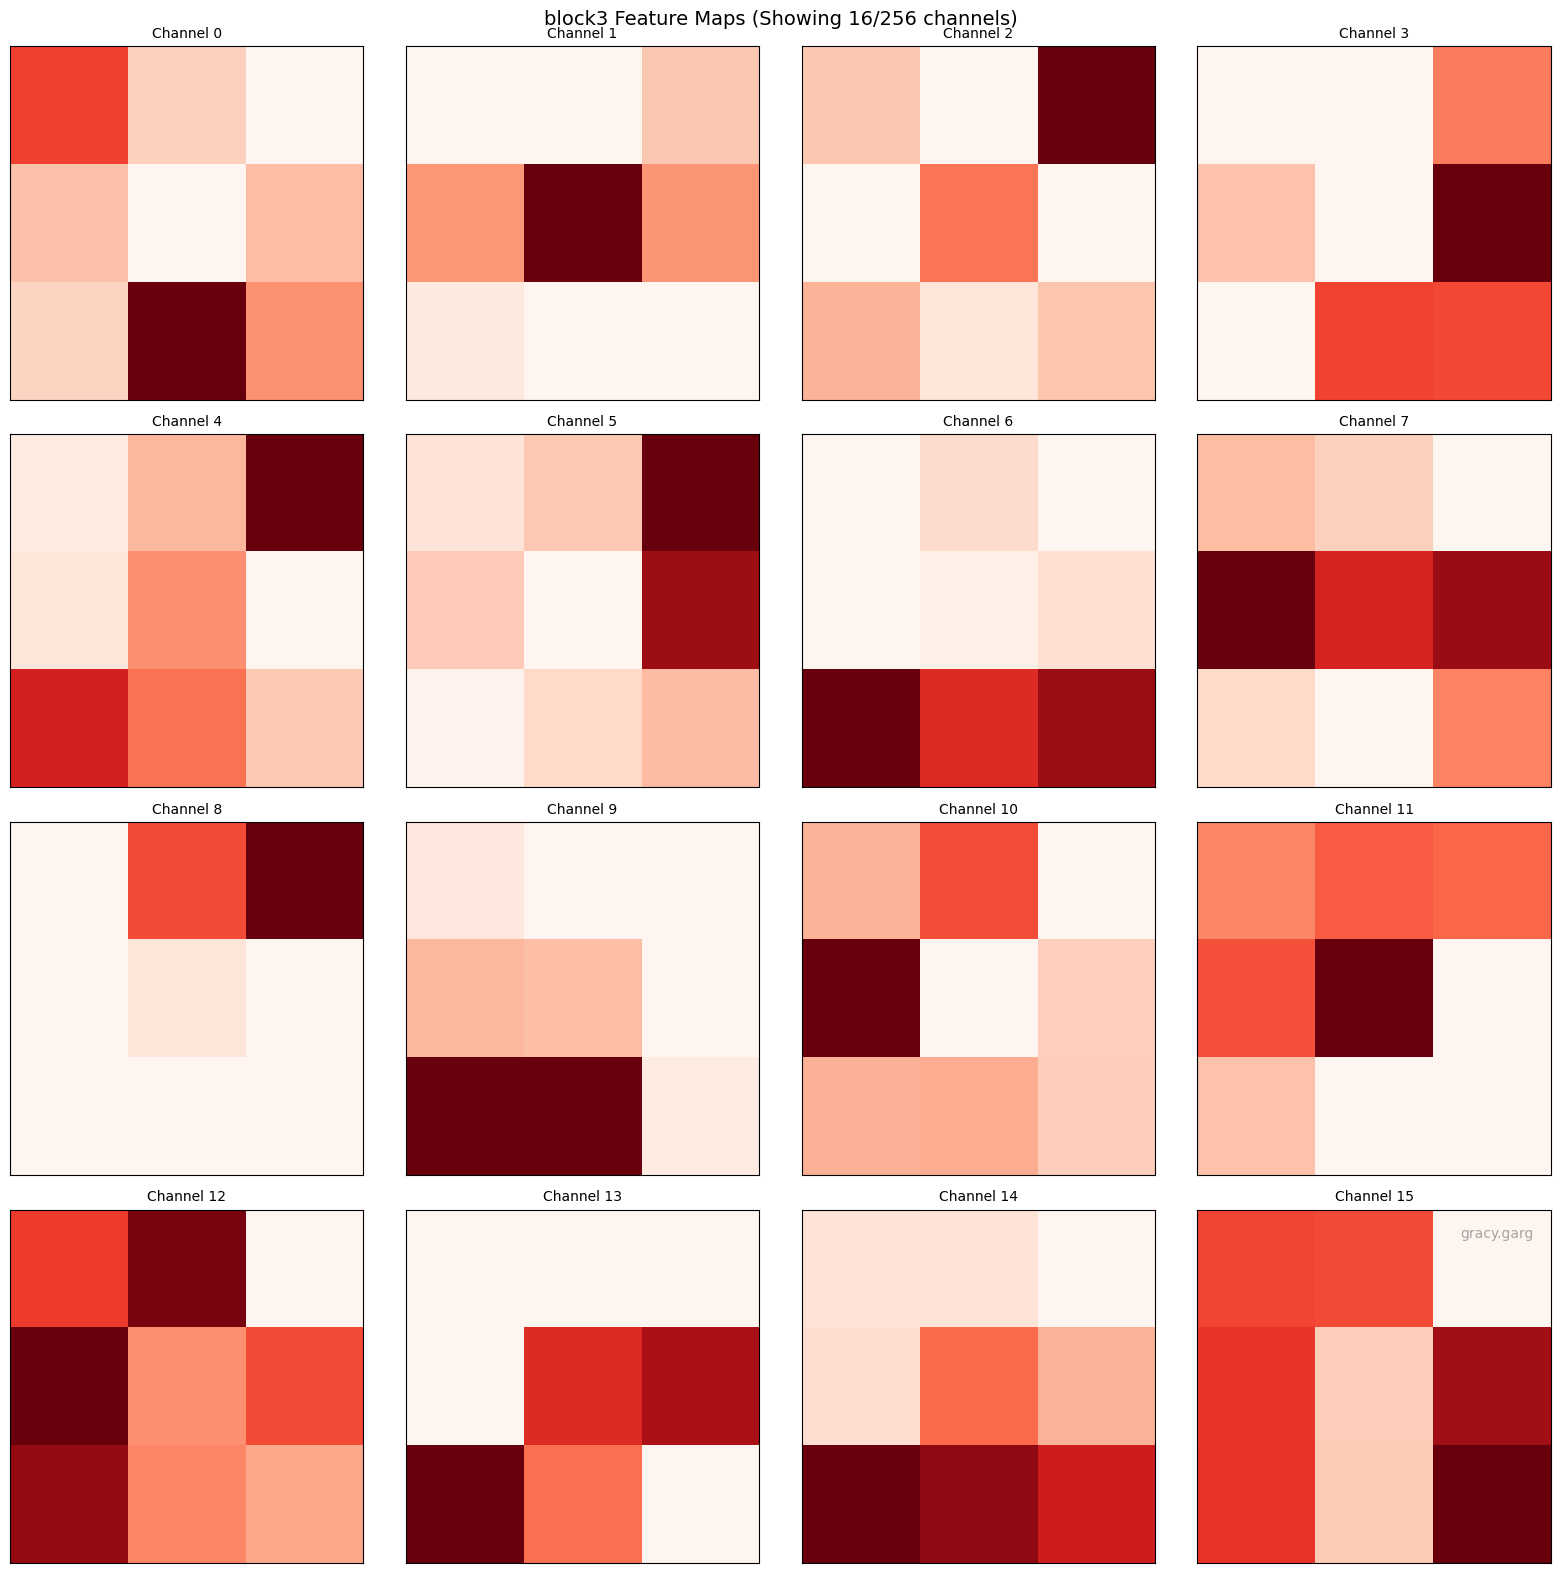


=== Test Image 2 ===
Ground Truth: Trouser
Predicted: Trouser
Ink Target: 0.2087
Regression Prediction: 0.1982


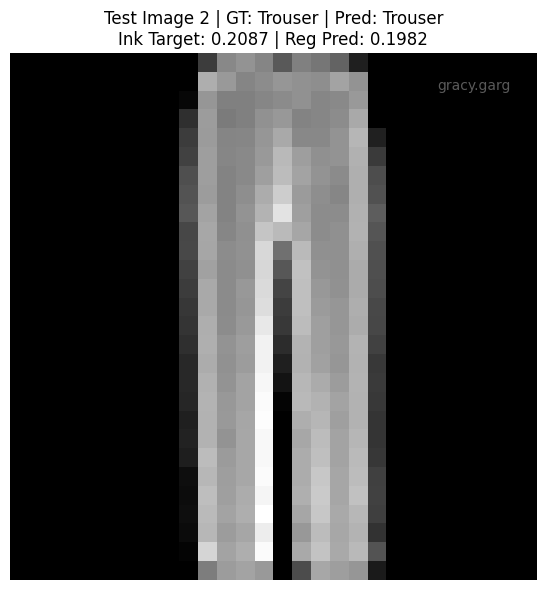


block1: 64 channels, Feature map size: 14x14


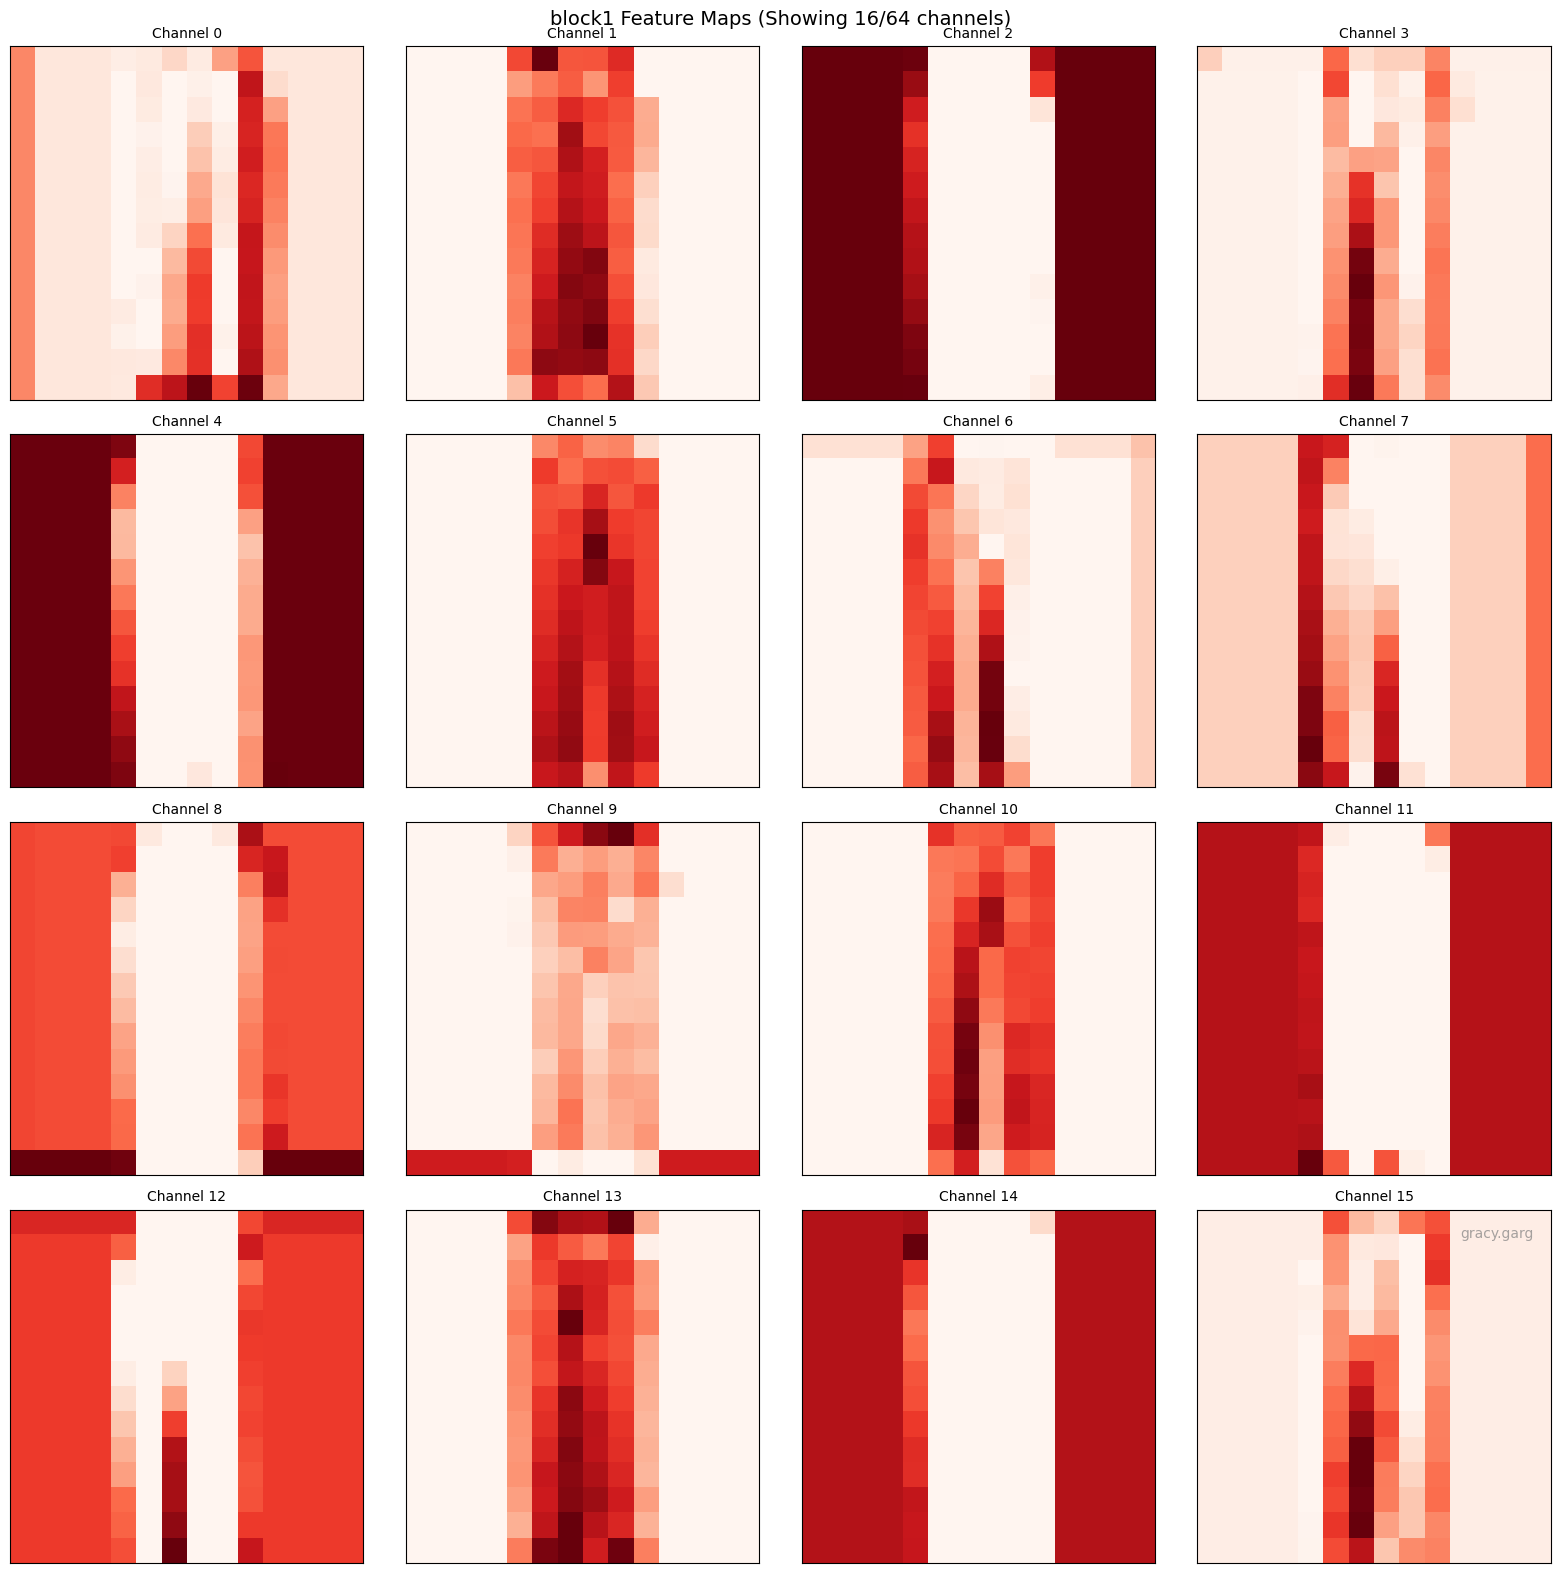


block2: 128 channels, Feature map size: 7x7


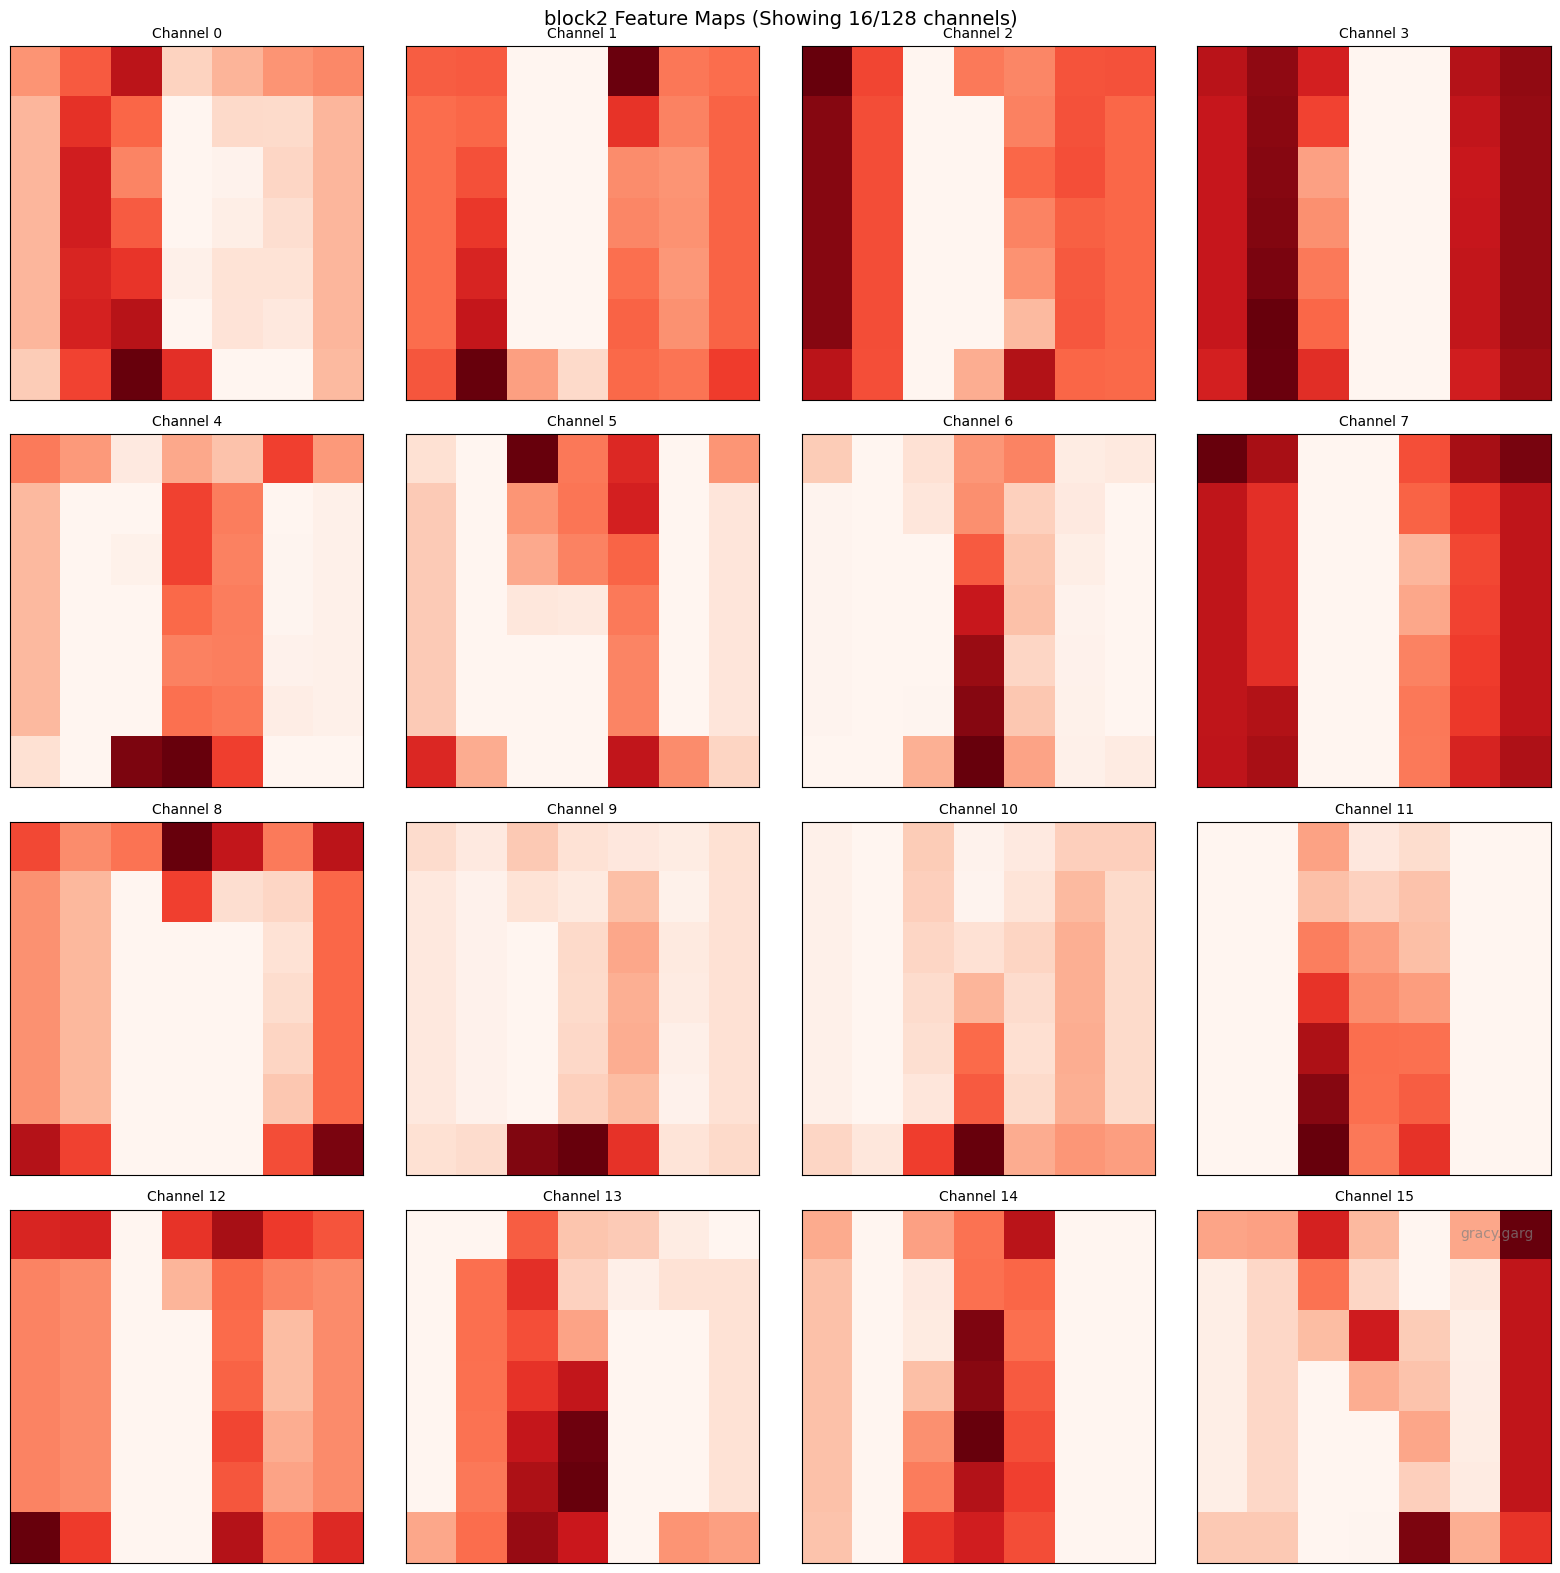


block3: 256 channels, Feature map size: 3x3


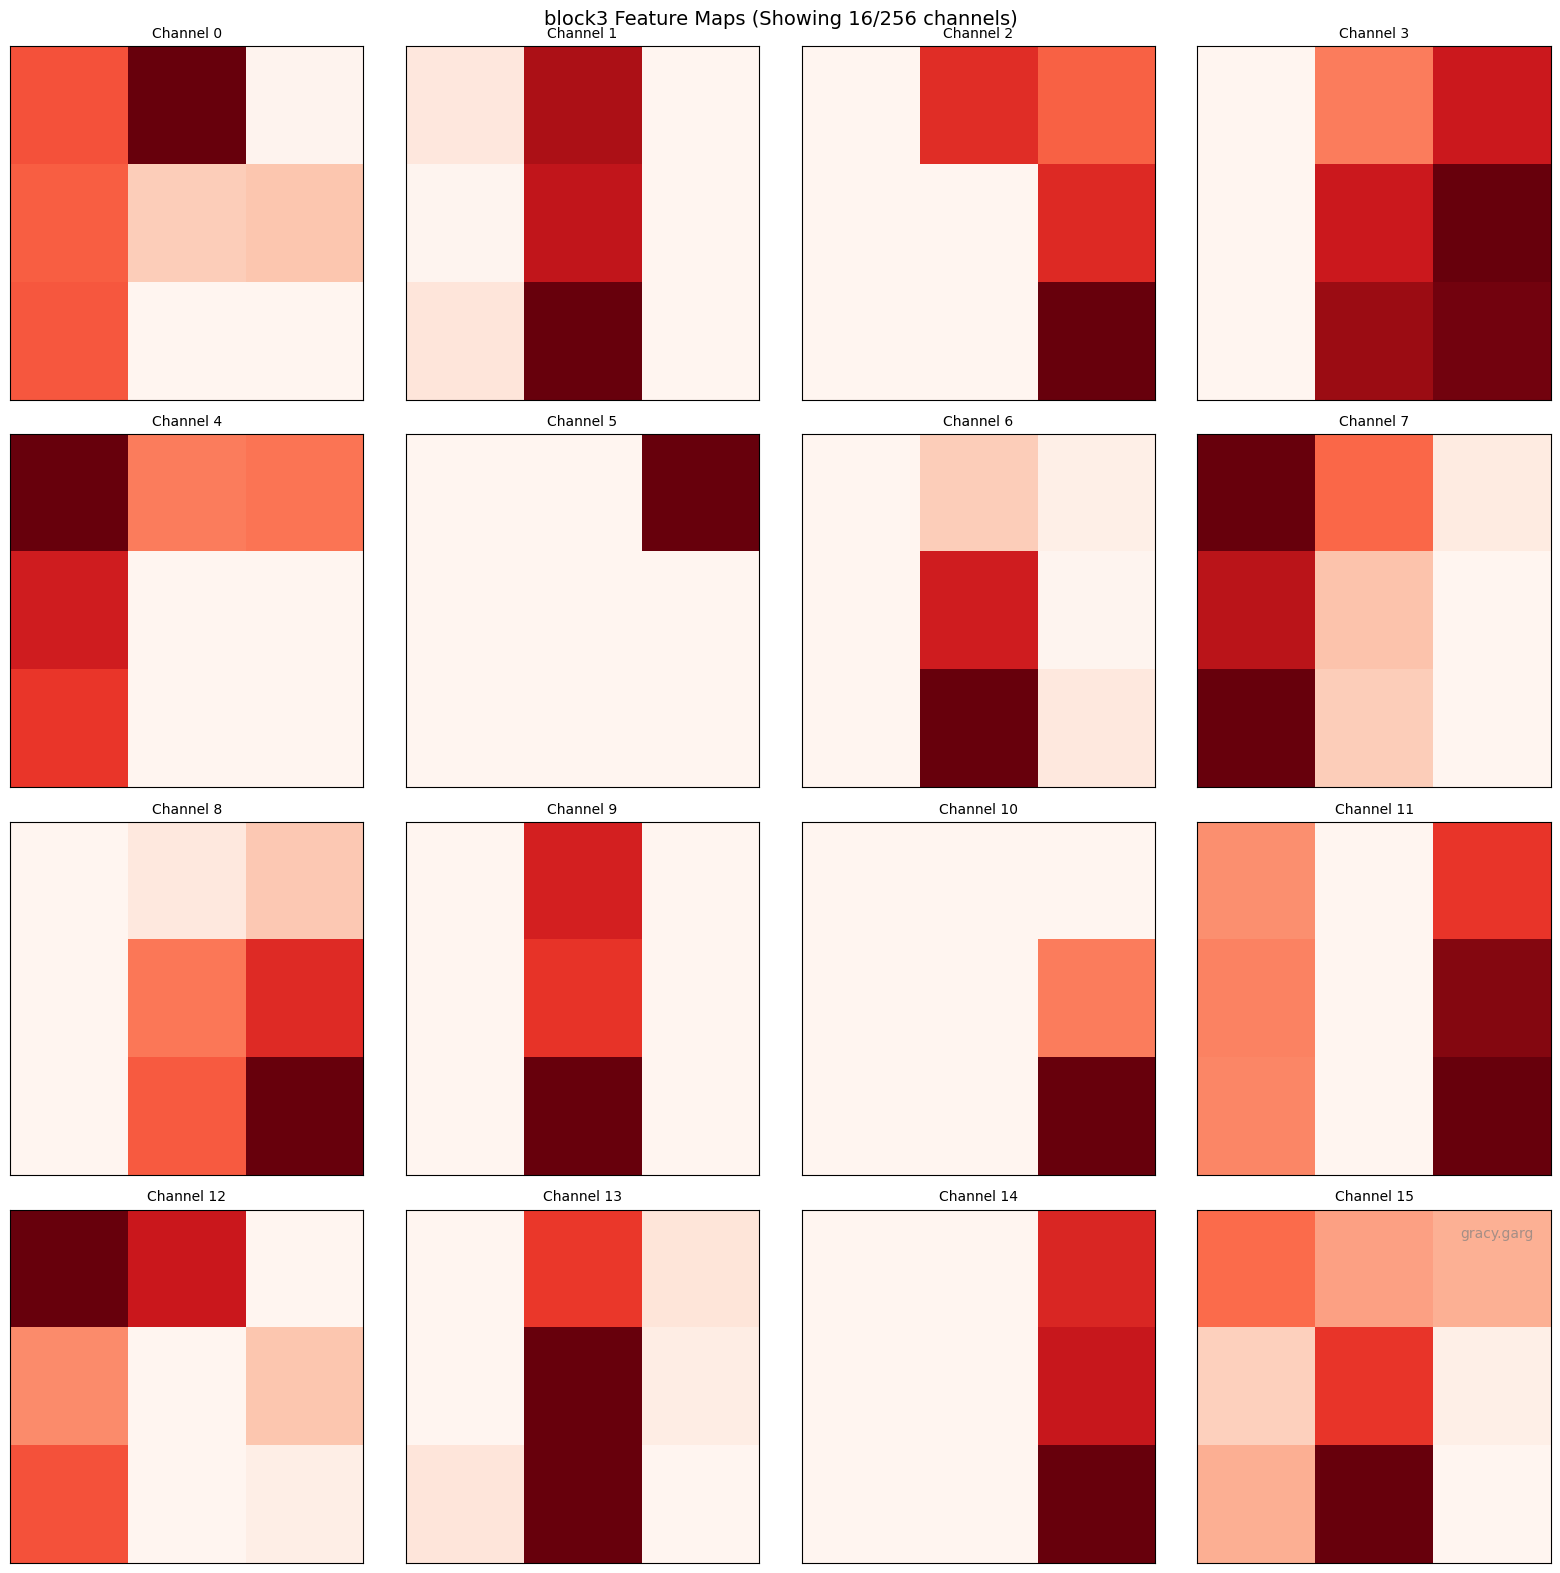


=== Test Image 3 ===
Ground Truth: T-shirt/top
Predicted: T-shirt/top
Ink Target: 0.4610
Regression Prediction: 0.3756


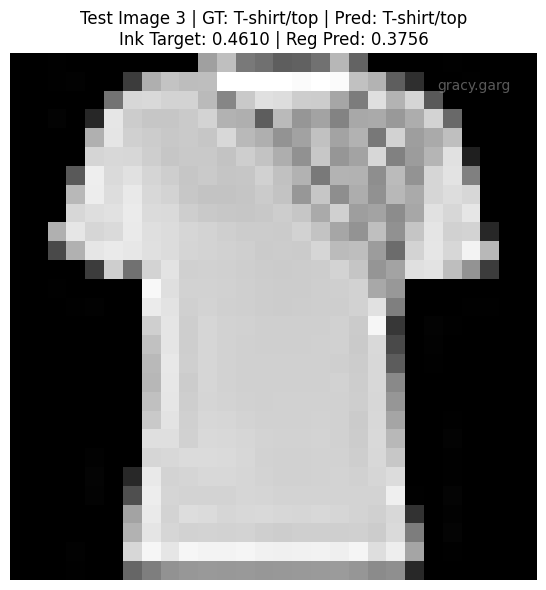


block1: 64 channels, Feature map size: 14x14


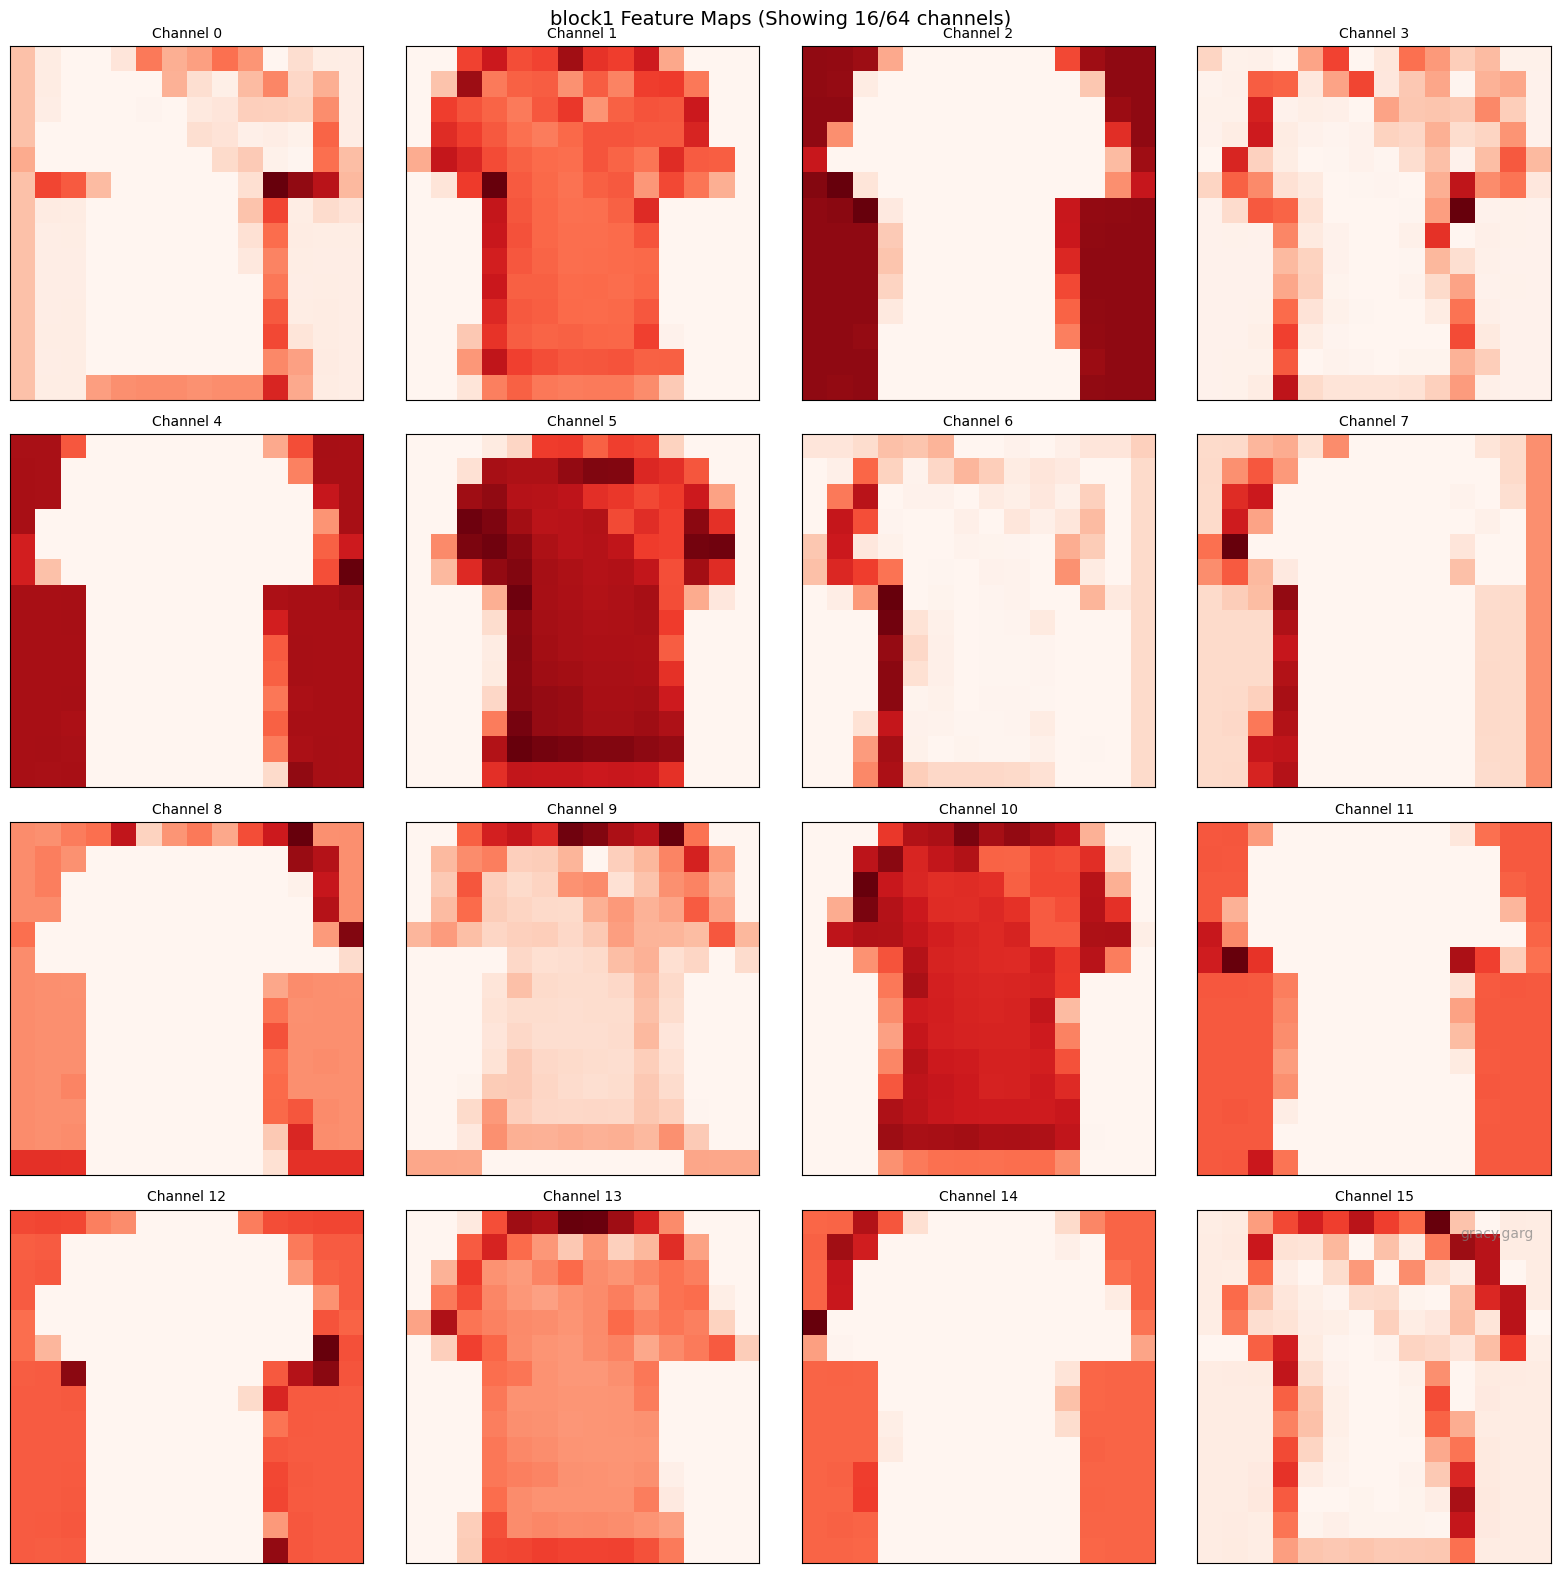


block2: 128 channels, Feature map size: 7x7


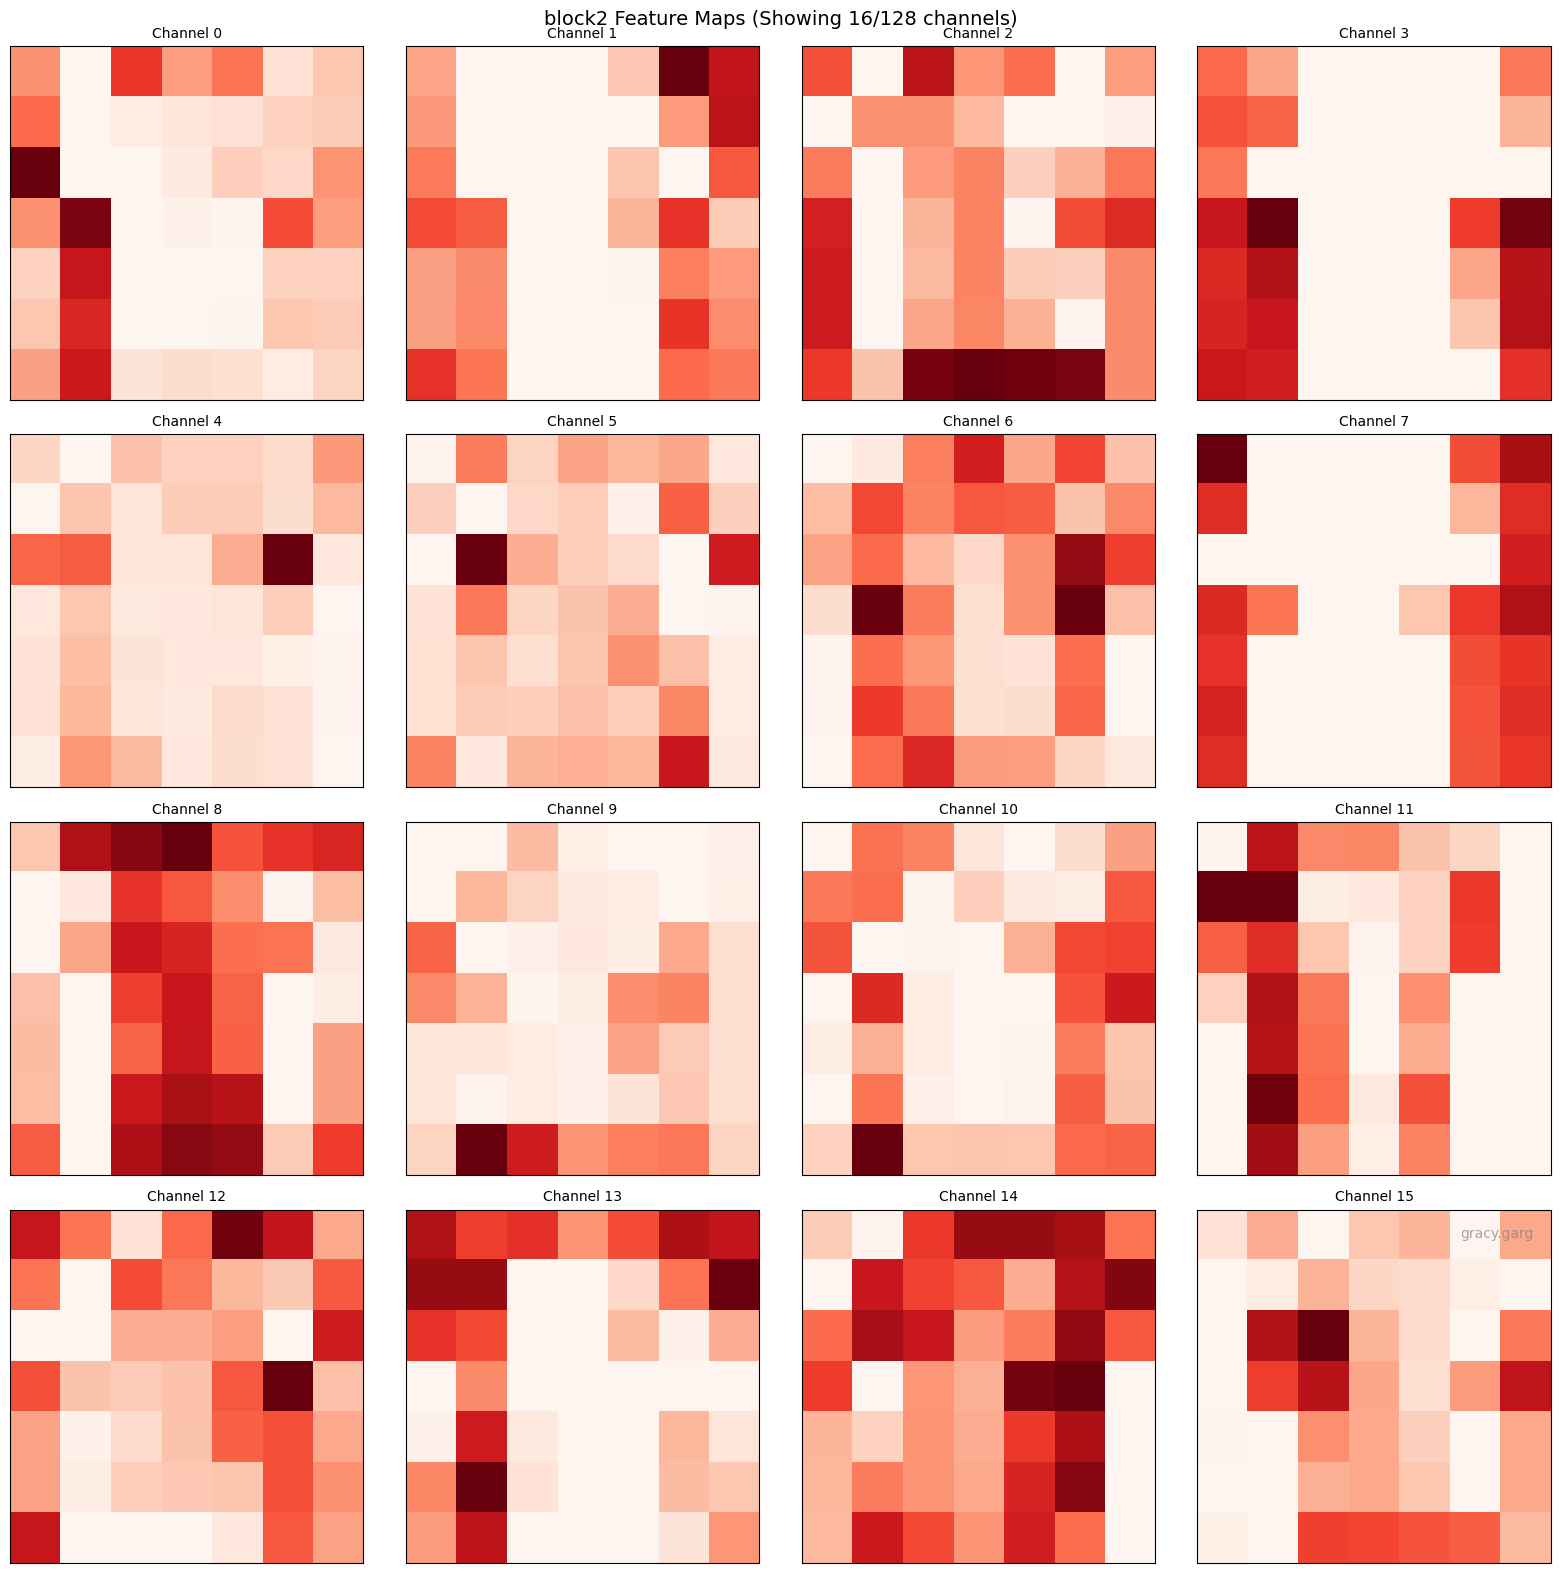


block3: 256 channels, Feature map size: 3x3


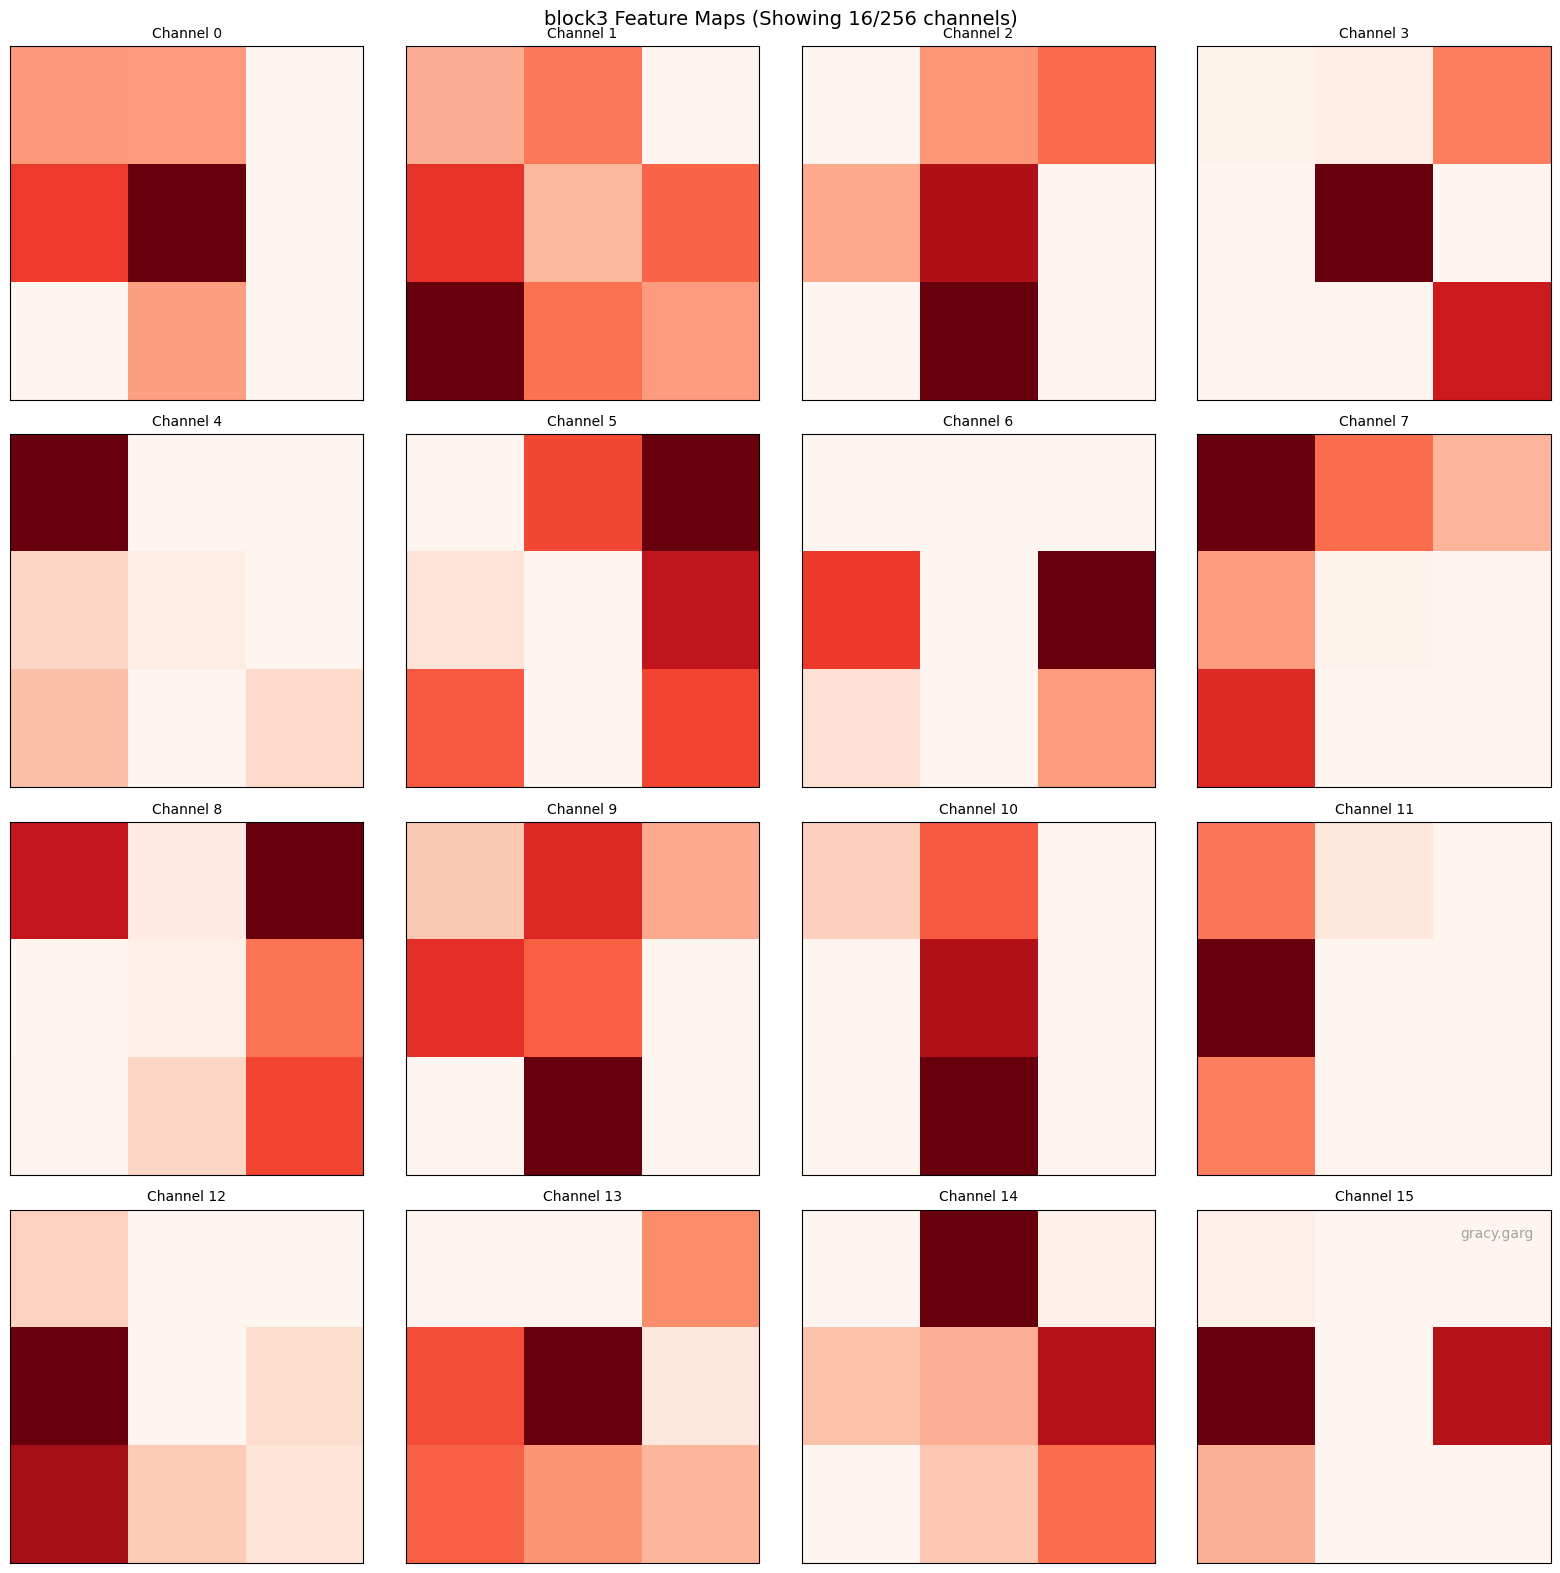


2. Detailed Visualization (first image only):


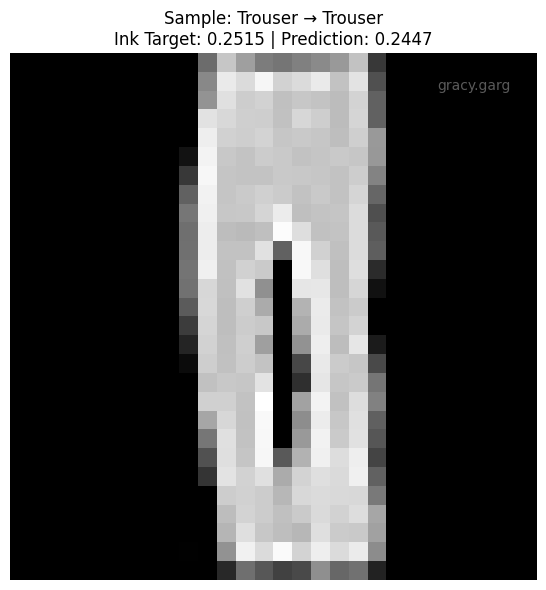


Feature Map Details:
block1: torch.Size([1, 64, 14, 14]) (channels × height × width)
block2: torch.Size([1, 128, 7, 7]) (channels × height × width)
block3: torch.Size([1, 256, 3, 3]) (channels × height × width)


In [18]:
def visualize_feature_maps(model: MultiTaskCNN, test_loader: torch.utils.data.DataLoader, device: torch.device):
    """
    Visualizes intermediate feature maps from each convolutional block 
    for three randomly selected test images (Q1.5.1).
    """
    model.eval()
    model.to(device)  # Ensure model is on correct device

    test_data = test_loader.dataset 
    all_indices = list(range(len(test_data)))
    selected_indices = random.sample(all_indices, 3) 

    # Prepare class names for titles
    class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
                   'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

    for img_idx, data_idx in enumerate(selected_indices):
        norm_image, label, ink_target = test_data[data_idx]
        image_batch = norm_image.unsqueeze(0).to(device)  # Move input to device
        
        # --- Run the Forward Pass to Extract Features ---
        with torch.no_grad():
            # Using return_features=True
            cls_logits, reg_pred, feature_maps = model(image_batch, return_features=True) 

        # Denormalize image for display
        denorm_image_np = (norm_image * FASHION_STD + FASHION_MEAN).squeeze().cpu().numpy()
        predicted_class = torch.argmax(cls_logits, dim=1).item()
        
        print(f"\n=== Test Image {img_idx+1} ===")
        print(f"Ground Truth: {class_names[label]}")
        print(f"Predicted: {class_names[predicted_class]}")
        print(f"Ink Target: {ink_target.item():.4f}")
        print(f"Regression Prediction: {reg_pred.item():.4f}")
        
        # --- Plot Original Image ---
        fig, ax = plt.subplots(1, 1, figsize=(8, 6))
        ax.imshow(denorm_image_np, cmap='gray')
        ax.set_title(
            f"Test Image {img_idx+1} | GT: {class_names[label]} | Pred: {class_names[predicted_class]}\n"
            f"Ink Target: {ink_target.item():.4f} | Reg Pred: {reg_pred.item():.4f}", 
            fontsize=12
        )
        ax.axis('off')
        add_username_to_plot(username)
        plt.tight_layout()
        plt.show()
        
        # --- Plot Feature Maps for Each Block ---
        block_names = list(feature_maps.keys())
        
        for i, block_name in enumerate(block_names):
            features_tensor = feature_maps[block_name].squeeze(0).cpu()  # Move to CPU for plotting
            num_channels = features_tensor.shape[0]
            
            print(f"\n{block_name}: {num_channels} channels, "
                  f"Feature map size: {features_tensor.shape[1]}x{features_tensor.shape[2]}")
            
            # Display up to 16 feature maps for better visibility
            features_to_plot = min(num_channels, 16)
            cols = 4
            rows = int(np.ceil(features_to_plot / cols))
            
            # Create figure for this block's feature maps
            fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
            fig.suptitle(f'{block_name} Feature Maps (Showing {features_to_plot}/{num_channels} channels)', 
                        fontsize=14, y=0.98)
            
            # Handle case where we have only one row
            if rows == 1:
                axes = axes.reshape(1, -1)
            
            # Plot feature maps
            for j in range(features_to_plot):
                row = j // cols
                col = j % cols
                
                feature_map = features_tensor[j].numpy()
                
                axes[row, col].imshow(feature_map, cmap='Reds')
                axes[row, col].set_title(f'Channel {j}', fontsize=10)
                axes[row, col].set_xticks([])
                axes[row, col].set_yticks([])
            
            # Hide unused subplots
            for j in range(features_to_plot, rows * cols):
                row = j // cols
                col = j % cols
                axes[row, col].axis('off')
            
            add_username_to_plot(username)
            plt.tight_layout()
            plt.show()

# --- Improved Visualization with Summary ---
def visualize_feature_maps_summary(model: MultiTaskCNN, test_loader: torch.utils.data.DataLoader, device: torch.device):
    """
    Creates a compact summary visualization of feature maps.
    """
    model.eval()
    model.to(device)

    test_data = test_loader.dataset 
    selected_indices = random.sample(list(range(len(test_data))), 5)  # Just one image for summary
    
    class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
                   'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

    data_idx = selected_indices[0]
    norm_image, label, ink_target = test_data[data_idx]
    image_batch = norm_image.unsqueeze(0).to(device)
    
    # --- Run the Forward Pass to Extract Features ---
    with torch.no_grad():
        cls_logits, reg_pred, feature_maps = model(image_batch, return_features=True) 

    # Denormalize image for display
    denorm_image_np = (norm_image * FASHION_STD + FASHION_MEAN).squeeze().cpu().numpy()
    predicted_class = torch.argmax(cls_logits, dim=1).item()
    
    # --- Create Summary Plot ---
    block_names = list(feature_maps.keys())
    
    # Calculate grid size: 1 original + 3 blocks, each showing 4 feature maps
    fig, axes = plt.subplots(4, 5, figsize=(20, 16))
    fig.suptitle(f'Feature Map Analysis: {class_names[label]} → {class_names[predicted_class]}', fontsize=16)
    
    # Plot original image (first row, center)
    axes[0, 2].imshow(denorm_image_np, cmap='gray')
    axes[0, 2].set_title(f'Original Image\nGT: {class_names[label]} | Pred: {class_names[predicted_class]}\n'
                         f'Ink: {ink_target.item():.3f} | Pred: {reg_pred.item():.3f}')
    axes[0, 2].axis('off')
    
    # Hide other subplots in first row
    for col in [0, 1, 3, 4]:
        axes[0, col].axis('off')
    
    # Plot feature maps for each block
    for block_idx, block_name in enumerate(block_names):
        features_tensor = feature_maps[block_name].squeeze(0).cpu()
        num_channels = features_tensor.shape[0]
        
        # Select 4 representative channels (spread across the range)
        if num_channels >= 4:
            channel_indices = [0, num_channels//3, 2*num_channels//3, num_channels-1]
        else:
            channel_indices = list(range(num_channels))
        
        row = block_idx + 1  # Start from second row
        
        for col_idx, channel_idx in enumerate(channel_indices):
            if col_idx < 4:  # Only plot first 4
                feature_map = features_tensor[channel_idx].numpy()
                axes[row, col_idx].imshow(feature_map, cmap='Reds')
                axes[row, col_idx].set_title(f'{block_name}\nCh {channel_idx}')
                axes[row, col_idx].set_xticks([])
                axes[row, col_idx].set_yticks([])
        
        # Add block info in the last column
        axes[row, 4].text(0.1, 0.5, 
                         f'{block_name}\n'
                         f'Channels: {num_channels}\n'
                         f'Size: {features_tensor.shape[1]}×{features_tensor.shape[2]}\n'
                         f'Range: [{features_tensor.min():.3f}, {features_tensor.max():.3f}]',
                         transform=axes[row, 4].transAxes,
                         fontsize=10, verticalalignment='center')
        axes[row, 4].axis('off')
        
        # Hide unused columns for this row if less than 4 channels
        for col_idx in range(len(channel_indices), 4):
            axes[row, col_idx].axis('off')
    
    add_username_to_plot(username)
    plt.tight_layout()
    plt.show()

# --- Visualization Execution ---
# You need to fill these in manually after checking your runs table!
BEST_CLS_CONFIG = {
    'base_filters': 64,  # Example: The filter count used by your highest accuracy run
    'dropout_rate': 0.3, # Example: The dropout used
    'checkpoint_filename': 'model_checkpoints/BEST_L10.1_L20.5_AdamW_loss0.0304_20251103_211601.pth' # Rename to match your saved file
}

# 2. INSTANTIATE AND LOAD THE TRAINED MODEL

print("Loading Best Classification Model for Visualization...")
model_for_vis = MultiTaskCNN(
    base_filters=BEST_CLS_CONFIG['base_filters'], 
    dropout_rate=BEST_CLS_CONFIG['dropout_rate']
)

# IMPORTANT: Move model to the same device as your data
model_for_vis = model_for_vis.to(device)

try:
    # CRITICAL: Load the state dict from the saved file
    # This is where you would load the file saved in Step 1.
    model_for_vis.load_state_dict(torch.load(BEST_CLS_CONFIG['checkpoint_filename'], map_location=device))
    print(f"Successfully loaded trained weights from {BEST_CLS_CONFIG['checkpoint_filename']}")
    
    # 3. RUN THE VISUALIZATION
    # We must ensure test_loader is still defined globally
    visualize_feature_maps(model_for_vis, test_loader, device) 

except FileNotFoundError:
    print("\nERROR: Checkpoint file not found.")
    print(f"Please ensure you run the sweep and save a checkpoint matching: {BEST_CLS_CONFIG['checkpoint_filename']}")
    print("For now, using an untrained model for visualization...")
    
    # Use untrained model for demonstration
    model_for_vis.eval()
    print("\n1. Summary Visualization (Untrained Model):")
    visualize_feature_maps_summary(model_for_vis, test_loader, device)
    
except Exception as e:
    print(f"\nERROR loading model state: {e}")
    print("For now, using an untrained model for visualization...")
    
    # Use untrained model for demonstration
    model_for_vis.eval()
    print("\n1. Summary Visualization (Untrained Model):")
    visualize_feature_maps_summary(model_for_vis, test_loader, device)


print("\n2. Detailed Visualization (first image only):")
# Run detailed visualization for just one image to avoid too much output
test_data = test_loader.dataset 
selected_idx = random.randint(0, len(test_data)-1)
norm_image, label, ink_target = test_data[selected_idx]
image_batch = norm_image.unsqueeze(0).to(device)

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Ensure model is in eval mode and on correct device
model_for_vis.eval()
model_for_vis = model_for_vis.to(device)

with torch.no_grad():
    cls_logits, reg_pred, feature_maps = model_for_vis(image_batch, return_features=True)

denorm_image_np = (norm_image * FASHION_STD + FASHION_MEAN).squeeze().cpu().numpy()
predicted_class = torch.argmax(cls_logits, dim=1).item()

# Just show original image and feature map shapes
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.imshow(denorm_image_np, cmap='gray')
ax.set_title(f'Sample: {class_names[label]} → {class_names[predicted_class]}\n'
             f'Ink Target: {ink_target:.4f} | Prediction: {reg_pred.item():.4f}')
ax.axis('off')
add_username_to_plot(username)
plt.tight_layout()
plt.show()

# Print feature map information
print("\nFeature Map Details:")
for block_name, features in feature_maps.items():
    print(f"{block_name}: {features.shape} (channels × height × width)")

# Evaluating test metrics for best model A

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, accuracy_score
from math import sqrt

checkpoint_path = "model_checkpoints/BEST_L11_L20.5_AdamW_loss0.2869_20251103_211900.pth"
model = MultiTaskCNN(base_filters=64, dropout_rate=0.3)
state = torch.load(checkpoint_path, map_location=device)
model.load_state_dict(state)
model = model.to(device)
model.eval()

y_true_cls, y_pred_cls = [], []
y_true_reg, y_pred_reg = [], []

with torch.no_grad():
    for x, y_cls, y_reg in test_loader:
        x = x.to(device)
        logits, reg_output = model(x)

        preds_cls = torch.argmax(logits, dim=1)
        y_true_cls.extend(y_cls.cpu().numpy())
        y_pred_cls.extend(preds_cls.cpu().numpy())

        # flatten regression outputs/targets to 1-D lists
        y_true_reg.extend(y_reg.cpu().numpy().ravel())
        y_pred_reg.extend(reg_output.cpu().numpy().ravel())

test_acc = accuracy_score(y_true_cls, y_pred_cls)
mse = mean_squared_error(y_true_reg, y_pred_reg)   # returns MSE
test_rmse = sqrt(mse)                              # convert to RMSE
test_mae = mean_absolute_error(y_true_reg, y_pred_reg)

print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test MAE: {test_mae:.6f}")
print(f"Test RMSE: {test_rmse:.6f}")

Test Accuracy: 0.8903
Test MAE: 0.013172
Test RMSE: 0.016914


# Evaluating test metrics for best model B

In [28]:
from sklearn.metrics import mean_squared_error, accuracy_score
from math import sqrt

checkpoint_path = "model_checkpoints/BEST_L12_L21_Adam_loss0.6884_20251103_211254.pth"
model = MultiTaskCNN(base_filters=64, dropout_rate=0.3)
state = torch.load(checkpoint_path, map_location=device)
model.load_state_dict(state)
model = model.to(device)
model.eval()

y_true_cls, y_pred_cls = [], []
y_true_reg, y_pred_reg = [], []

with torch.no_grad():
    for x, y_cls, y_reg in test_loader:
        x = x.to(device)
        logits, reg_output = model(x)

        preds_cls = torch.argmax(logits, dim=1)
        y_true_cls.extend(y_cls.cpu().numpy())
        y_pred_cls.extend(preds_cls.cpu().numpy())

        # flatten regression outputs/targets to 1-D lists
        y_true_reg.extend(y_reg.cpu().numpy().ravel())
        y_pred_reg.extend(reg_output.cpu().numpy().ravel())

test_acc = accuracy_score(y_true_cls, y_pred_cls)
mse = mean_squared_error(y_true_reg, y_pred_reg)   # returns MSE
test_rmse = sqrt(mse)                              # convert to RMSE
test_mae = mean_absolute_error(y_true_reg, y_pred_reg)

print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test RMSE: {test_rmse:.5f}")
print(f"Test MAE: {test_mae:.5f}")

Test Accuracy: 0.8688
Test RMSE: 0.01640
Test MAE: 0.01276


# Q1 Final Analysis and Reporting



### Approach and Hyperparameters

Our goal was to explore the trade-off between classification ($\mathcal{L}_{CE}$) and regression ($\mathcal{L}_{MSE}$) tasks using the joint loss $\mathcal{L}_{total}=\lambda_{1}\mathcal{L}_{CE}+\lambda_{2}\mathcal{L}_{MSE}$. We utilized a **Multi-Task CNN** with a 3-block shared convolutional backbone.

To explore the hyperparameter space, we conducted **5 distinct training runs**, prioritizing minimum compute wastage by setting a fixed duration of 5 epochs per run. Key hyperparameters varied include the loss weights ($\lambda_1, \lambda_2$), Learning Rate (LR), and the base number of convolutional filters (`base_filters`). All runs were logged to **Weights & Biases (wandb)**.

|              Run ID             | $\lambda_1$ (CE) | $\lambda_2$ (MSE) |  LR  | Optimizer | Base Filters | Focus / Priority                                |
| :-----------------------------: | :--------------: | :---------------: | :--: | :-------: | :----------: | :---------------------------------------------- |
|  **Run 1 – L1_1_L2_0.5_AdamW**  |        1.0       |        0.5        | 3e-3 |   AdamW   |      64      | Favors **Classification**, higher complexity    |
|    **Run 2 – L1_1_L2_2_Adam**   |        1.0       |        2.0        | 1e-3 |    Adam   |      32      | Favors **Regression**                           |
| **Run 3 – L1_0.1_L2_0.5_AdamW** |        0.1       |        0.5        | 1e-3 |   AdamW   |      64      | **Strongly Favors Regression**, low CE emphasis |
|   **Run 4 – L1_2_L2_2_AdamW**   |        2.0       |        2.0        | 5e-4 |   AdamW   |      64      | Balanced but slightly **CE-dominant**           |
|  **Run 5 – L1_0.1_L2_2_AdamW**  |        0.1       |        2.0        | 1e-3 |   AdamW   |      32      | Extreme **Regression priority**                 |




## Q1.4: Model Selection and Trade-Off Discussion

After conducting 5 distinct runs with varying weighting factors (lambda1, lambda2), 
we performed model selection based on the validation metrics:

|         Model ID        | Lambda1 ($\mathcal{L}_{CE}$) | Lambda2 ($\mathcal{L}_{MSE}$) | Val Acc (Max) | Val RMSE (Min) | Test Acc | Test RMSE | Trade-off Effect                                                                               |
| :---------------------: | :--------------------------: | :---------------------------: | :-----------: | :------------: | :------: | :-------: | :--------------------------------------------------------------------------------------------- |
|  **Model A (Best Acc)** |            **1.0**           |            **0.5**            |   **0.894**   |   **0.01698**  |    0.8903  |     0.01691     | Highest classification priority led to maximum accuracy, but slightly higher regression error. |
| **Model B (Best RMSE)** |            **2.0**           |            **1.0**            |   **0.8687**  |   **0.01674**  |      0.8688    |     0.01640     | Emphasis on regression yielded lowest RMSE, but slightly reduced classification accuracy.      |

## **Discussion of the $\lambda_1, \lambda_2$ Trade-Off**

The experiments demonstrate a clear trade-off between classification accuracy and regression precision in the multi-task learning setup:

When $\lambda_1$ (classification weight) was higher (e.g., Model A: $\lambda_1=1.0, \lambda_2=0.5$), the model learned features that maximized class separation, achieving the highest accuracy (0.894). However, this came at the cost of a slightly higher RMSE (0.01698), showing less precision in predicting continuous ink density.

When $\lambda_2$ (regression weight) was increased (e.g., Model B: $\lambda_1=2.0, \lambda_2=1.0$), the model optimized for smoother ink predictions, achieving the lowest RMSE (0.01674), but its accuracy dropped slightly to 0.8687 due to reduced emphasis on discriminative class features.

Hence, the trade-off highlights that increasing $\lambda_2$ improves regression at the expense of classification, and vice versa. The ideal setting depends on whether the task prioritizes precise continuous prediction (ink regression) or categorical accuracy (clothing classification).

## Q1.5: Feature Map Interpretation

Feature maps were extracted from a trained model for three test images.

1.  **Block 1 (Low-Level Features, e.g., 32 channels, 14x14):** These maps capture basic visual primitives: sharp horizontal and vertical edges, corners, and bright/dark spots. These features are fundamental for defining the initial boundaries of the clothing item.
2.  **Block 2 (Mid-Level Features, e.g., 64 channels, 7x7):** Activations here show combinations of Block 1 features, forming components like curves, distinct texture patches (e.g., knitwear patterns), and partial shapes (e.g., the strap of a sandal or a boot sole). These help distinguish object categories.
3.  **Block 3 (High-Level Features, e.g., 128 channels, 3x3):** These maps represent semantic concepts, such as the overall silhouette of a specific garment (e.g., the general outline of a coat vs. a bag). These highly condensed features are vital for both:
    * **Classification:** Identifying the object category based on overall shape.
    * **Ink Regression:** Since high-level features represent the full object area, their activation intensity is directly proportional to the "ink" or total pixel mass, making them crucial for accurate regression prediction.
"""

# WandB Link

URL for project workspace

https://wandb.ai/gracygarg6516-iiit-hyderabad/SMAI-A4?nw=nwusergracygarg6516 

All results have been reported according to the latest sweep as evaluated in : 


https://wandb.ai/gracygarg6516-iiit-hyderabad/SMAI-A4/sweeps/2hi53gi2?nw=nwusergracygarg6516
